# Markets, morality and the complexity–efficiency trade-off of languages

This notebook combines two papers:

* **Enke, B. (2023).** *Market exposure and human morality.* Nature Human Behaviour 7, 134–141.
  Market exposure (intercommunity trade and money) of pre-industrial societies goes together with
  prosociality, trust, universalist values and moral emotions.
* **Koplenig, A., Wolfer, S., Rüdiger, J. O. & Meyer, P. (2025).** *Human languages trade off complexity
  against efficiency.* PLOS Complex Systems 2(2): e0000032. Languages with a higher **entropy rate**
  (complexity, bits per symbol) need **fewer symbols** to say the same thing (efficiency), and the
  social environment (speaker population) shifts languages along this trade-off.

It answers two questions:

1. **Q1 –** Do languages of societies with more market exposure, or with stronger moral values, differ in
   complexity (entropy rate *h*) and efficiency (text length *L*)?
2. **Q2 –** Are **moral phrases** more or less complex/efficient than the rest of the text, how does this vary
   across languages, and is that variation related to market exposure?

## How the two papers are joined

| Ingredient | Original paper | What this notebook uses |
|---|---|---|
| Parallel text | Koplenig: 41 corpora incl. *BibleNT* (Parallel Bible Corpus, restricted) | New Testament from the open **eBible corpus** (verse-aligned, same text type as *BibleNT*) |
| Complexity *h* | Koplenig Eq. 5: bits to code 2nd half given 1st half ÷ length of 2nd half; PPM2, PPM6, PAQ, LSTM, Transformers | Same estimator with **PPM order 2, PPM order 6** (`pyppmd`, same algorithm family) and **LZMA**; characters, words, BPE |
| Efficiency *L* | length of the parallel text in characters / words | same |
| Market exposure | Enke: share of market concepts in folklore (Berezkin catalogue), validated against SCCS trade & money codes | **Open rebuild from D-PLACE**: SCCS *intercommunity trade* + *money* (the codes Enke validates against), SCCS market exchange, Carneiro trade/markets/money, Binford money. **Enke's own index is used automatically if you put his file in `data/enke/`** |
| Moral values | Enke: folklore salience of prosociality, trust, universalism, moral emotions | Open proxies: SCCS child-training values (**generosity, trust, honesty**; Barry et al. 1976 and later codes), **obedience** (a particularist value), Ethnographic Atlas **moralizing high gods**. Enke's indices used automatically if supplied |
| Linking | — | society → Glottolog glottocode → ISO 639-3 → Bible translation |
| Statistics | Koplenig: lasso-selected controls, Kelejian–Prucha Moran tests (geographic, phylogenetic), eigenvector spatial filtering, multilevel models with AIC model averaging | Same, in Python (`scikit-learn`, `statsmodels`) |

**Read the results as an exploration, not a replication.** The open measures are proxies for Enke's folklore
indices, and the samples are much smaller than in either paper (tens to a couple of hundred languages).

## Main findings (from the full run on 193 languages)

**Replication.** Koplenig et al.'s complexity–efficiency trade-off is clearly present in this sample: languages with a
higher entropy rate need fewer symbols for the same New Testament (r ≈ −0.8 at every level; ρ_both ≈ −0.67 to −0.79
after controls and geographic + phylogenetic filtering). Rankings of languages by entropy are also very similar across
the three language models (r = 0.79–0.97).

**Q1 – languages vs market exposure and moral values.**
* *Markets.* Languages of more market-exposed societies sit at the "complex but efficient" end of the trade-off:
  higher entropy per character (median ≈ 1.55 vs 1.30 bits/char) and about 30 % shorter texts. Much of this raw
  difference (r ≈ ±0.5) is shared with geography and language family. What survives most consistently is the
  **word level**: more market exposure → more information per word and fewer words (model-averaged β ≈ +0.25 to +0.40
  for h_word, −0.18 to −0.35 for L_word, p ≈ .03–.13). This is the same direction Koplenig et al. found for speaker
  population size, but none of these effects survives correction for multiple testing (q ≥ .14), and only 39–68 languages
  have market data.
* *Moral values.* Child-training values (generosity, trust, honesty; n = 30) show no clear relation. The
  universalism proxy (n = 26) goes the *other* way from markets: fewer, simpler words and longer texts (q ≤ .03).
  Societies with **moralizing high gods** (n = 119) have languages with more information per word and fewer words
  (β = +0.48 and −0.44, q < .001) — the clearest Q1 result, probably reflecting morphological type (fewer, longer word forms).

**Q2 – moral phrases vs the rest.**
* *Efficiency.* In **every one** of the 192 non-English languages, moral verses need more characters than matched
  non-moral verses (≈ 8 % more, relative to English, p < 10⁻¹²); for all moral categories except prosocial this is
  significant. English expresses moral content unusually compactly compared with most languages.
* *Complexity.* Per character, moral verses are about as complex as the rest on average; the sign depends on the model
  and category. Robust across models: **trust** and **moral-emotion** verses are *less* complex per character. Within
  languages the trade-off reappears: where moral content takes more characters it carries fewer bits per character
  (corr(Δh, ΔL) ≈ −0.82; ρ_both ≈ −0.66) — but not fully: moral content still costs ≈ 7–8 % more bits in total.
* *Markets.* In languages of more market-exposed societies, moral passages are relatively **more** information-dense per
  character (pooled index: β = +0.29, p = .006, q = .05; ρ_both = +0.30). This holds with PPM-6 under both moral
  taggings but is weak with PPM-2, so it is suggestive rather than established. The universalism proxy again goes the
  opposite way (β = −0.41, q < .001, robust across models and taggings).

**Bottom line.** The data support Koplenig et al.'s trade-off and are consistent with markets (like population size)
moving languages toward the complex-but-efficient end, but with open proxies and small samples the market and
morality effects are tentative. Section 10 gives the full numbers and Section 11 the caveats.

## Running it
Run all cells top to bottom (*Kernel → Restart & Run All*). With the bundled data in `data/` no internet is
needed. A full run takes roughly 15–40 minutes on a typical laptop (most of it is compression in Section 4);
results are cached in `results/`, so re-runs are fast.

## 0. Settings

In [1]:
import os, re, io, sys, time, json, lzma, math, random, warnings, unicodedata, itertools
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm, chi2

import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.linear_model import Lasso
from joblib import Parallel, delayed

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200, 'display.max_columns', 40)

BASE = Path.cwd()
DATA = BASE / 'data'
RAW = DATA / 'raw'          # metadata and cultural data
BIBLE = DATA / 'bible'      # Bible texts (full .txt or bundled NT-only .nt.txt.xz)
ENKE_DIR = DATA / 'enke'    # OPTIONAL: put Enke's replication data here (Harvard Dataverse doi:10.7910/DVN/EEGV7A)
KOP_DIR = DATA / 'koplenig' # OPTIONAL: put Koplenig et al.'s entropy estimates here (https://osf.io/xdwjc/)
RES = BASE / 'results'
for d in (RAW, BIBLE, ENKE_DIR, KOP_DIR, RES):
    d.mkdir(parents=True, exist_ok=True)

# ---------------- user settings ----------------
MODE = 'full'            # 'core' = only languages with market / child-value data (~70 languages, faster)
                         # 'full' = also the Ethnographic Atlas moralizing-gods sample (~200 languages)
MODELS = ['ppm2', 'ppm6', 'lzma']   # language models (compressors) for Q1
LEVELS = ['char', 'word', 'bpe']    # information-encoding units (Koplenig Sect. 2.4)
Q2_MODELS = ['ppm6', 'ppm2']        # models for the moral-vs-rest comparison
Q2_SPLITS = 3            # random train/test splits of the non-moral verses in Q2 (more = more precise, slower)
MIN_NT_VERSES = 7000     # only (nearly) complete New Testaments
CORE_THRESHOLD = 0.90    # a verse is 'core' if usable in >= 90% of translations; translations need >= 90% of core
ENGLISH_TID = 'engwebp'  # World English Bible (public domain): reference text for moral tagging
N_JOBS = max(1, (os.cpu_count() or 2) - 1)   # parallel worker processes
ALLOW_DOWNLOAD = True    # set False to work strictly offline with what is in data/
SEED = 2026
MAX_LANGS = None         # e.g. 20 for a quick test run; None = all languages
# -----------------------------------------------
rng_global = np.random.default_rng(SEED)
print('Python', sys.version.split()[0], '| cores used:', N_JOBS, '| mode:', MODE)

Python 3.11.5 | cores used: 7 | mode: full


## 1. Data access

Every file is looked for locally first; only if it is missing is it downloaded (GitHub, with the jsDelivr
CDN as a mirror). If a download fails, the message tells you which URL to fetch by hand and where to save it.

In [2]:
import requests

GH = 'https://raw.githubusercontent.com'
def gh(repo, branch, path):
    return [f'{GH}/{repo}/{branch}/{path}', f'https://cdn.jsdelivr.net/gh/{repo}@{branch}/{path}']

def fetch(urls, dest, quiet=False):
    """Download the first URL that works to `dest` (skips if already present)."""
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return True
    if not ALLOW_DOWNLOAD:
        return False
    last = None
    for u in urls:
        for attempt in range(3):
            try:
                with requests.get(u, stream=True, timeout=90) as r:
                    r.raise_for_status()
                    tmp = dest.with_name(dest.name + '.part')
                    with open(tmp, 'wb') as f:
                        for chunk in r.iter_content(1 << 16):
                            f.write(chunk)
                    tmp.rename(dest)
                    return True
            except Exception as ex:
                last = ex
                time.sleep(1 + 2 * attempt)
    if not quiet:
        print(f'  !! could not download {dest.name}: {last}\n     -> fetch it manually from {urls[0]}\n        and save it as {dest}')
    return False

SOURCES = {
    'societies.csv':      gh('D-PLACE/dplace-cldf', 'master', 'cldf/societies.csv'),
    'dplace_data.csv':    gh('D-PLACE/dplace-cldf', 'master', 'cldf/data.csv'),          # 74 MB, only needed if the subset is missing
    'languages.csv':      gh('glottolog/glottolog-cldf', 'master', 'cldf/languages.csv'),
    'glottolog_values.csv': gh('glottolog/glottolog-cldf', 'master', 'cldf/values.csv'),  # 21 MB, only needed if the subset is missing
    'translations.csv':   gh('BibleNLP/ebible', 'main', 'metadata/translations.csv'),
    'vref.txt':           gh('BibleNLP/ebible', 'main', 'metadata/vref.txt'),
    'emfd_scoring.csv':   gh('medianeuroscience/emfd', 'master', 'dictionaries/emfd_scoring.csv'),
}
for name in ['societies.csv', 'languages.csv', 'translations.csv', 'vref.txt', 'emfd_scoring.csv']:
    fetch(SOURCES[name], RAW / name)
print(sorted(p.name for p in RAW.iterdir()))

['dplace_data_subset.csv', 'emfd_scoring.csv', 'glottolog_values_subset.csv', 'languages.csv', 'societies.csv', 'translations.csv', 'vref.txt']


## 2. Cultural data: market exposure and moral values (Enke side)

### 2.1 Open rebuild from D-PLACE
Enke's market index is the share of trade/money concepts in a society's folklore; he validates it against the
Standard Cross-Cultural Sample codes for **intercommunity trade (SCCS1)** and **money (SCCS17)**
(his Supplementary Table 1). Those codes, and related ones, are open in D-PLACE:

* Market exposure: SCCS1 trade as food source, SCCS17 money and credit, SCCS1733/1734 market exchange inside /
  outside the community; Carneiro: trade between communities, markets, standardized medium of exchange,
  coined money; Binford: use of money.
* Moral values: SCCS334–336 inculcation of **generosity, trust, honesty** (Barry et al. 1976), SCCS1761–1763
  (later codes on trust, generosity, honesty), SCCS322–325 **obedience**; EA034 **high gods** (code 4 = a
  moralizing high god that supports human morality).
* Controls (Ethnographic Atlas): community size (EA031), political hierarchy (EA033), dependence on
  agriculture (EA005). Enke uses community size and subsistence controls too.

In [3]:
VARS = {
    # market exposure
    'SCCS1': 'trade_food', 'SCCS17': 'money', 'SCCS1733': 'mkt_within', 'SCCS1734': 'mkt_outside',
    'CARNEIRO4_112': 'c_trade', 'CARNEIRO4_105': 'c_markets', 'CARNEIRO4_099': 'c_exchange_medium',
    'CARNEIRO4_100': 'c_coined_money', 'B033': 'b_money',
    # moral values
    'SCCS334': 'generosity', 'SCCS335': 'trust', 'SCCS336': 'honesty',
    'SCCS1761': 'trust2', 'SCCS1762': 'generosity2', 'SCCS1763': 'honesty2',
    'SCCS322': 'obed_eb', 'SCCS323': 'obed_eg', 'SCCS324': 'obed_lb', 'SCCS325': 'obed_lg',
    'EA034': 'high_god',
    # controls
    'EA031': 'community_size', 'EA033': 'jurisdiction', 'EA005': 'agriculture',
}

sub_path = RAW / 'dplace_data_subset.csv'
if not sub_path.exists():
    full = RAW / 'dplace_data.csv'
    if fetch(SOURCES['dplace_data.csv'], full):
        d = pd.read_csv(full, usecols=['Soc_ID', 'Var_ID', 'Value', 'Code_ID'], low_memory=False)
        d[d.Var_ID.isin(VARS)].to_csv(sub_path, index=False)
dpl = pd.read_csv(sub_path)
dpl = dpl[dpl.Var_ID.isin(VARS)]

def code_to_num(row):
    c = row.Code_ID
    if isinstance(c, str) and '-' in c:
        tail = c.rsplit('-', 1)[1]
        try:
            return float(tail)
        except ValueError:
            return np.nan        # 'NA' = missing
    try:
        return float(row.Value)
    except (TypeError, ValueError):
        return np.nan

dpl['num'] = dpl.apply(code_to_num, axis=1)
dpl.loc[dpl.Var_ID.isin(['SCCS1733', 'SCCS1734']), 'num'] = dpl['num'].map({10: 0, 20: 1, 21: 1, 22: 2})

soc = pd.read_csv(RAW / 'societies.csv')
# xd_id links the same society across EA, SCCS and Binford (Carneiro societies have no xd_id: they keep their own ID)
soc['key'] = soc.xd_id.fillna(soc.ID)
long = dpl.merge(soc[['ID', 'key']], left_on='Soc_ID', right_on='ID')
wide = long.pivot_table(index='key', columns='Var_ID', values='num', aggfunc='mean').rename(columns=VARS)
for c in VARS.values():
    if c not in wide: wide[c] = np.nan
print('societies with at least one variable:', len(wide))
wide.describe().T[['count', 'mean', 'min', 'max']]

societies with at least one variable: 1531


,count,mean,min,max
Var_ID,,,,
b_money,334.0,1.554890,1.0,4.0
c_exchange_medium,127.0,0.251969,0.0,1.0
c_coined_money,127.0,0.039370,0.0,1.0
c_markets,127.0,0.141732,0.0,1.0
c_trade,127.0,0.779528,0.0,1.0
agriculture,1289.0,4.457331,0.0,9.0
community_size,610.0,3.636066,1.0,8.0
jurisdiction,1154.0,1.944541,1.0,5.0
high_god,775.0,2.207742,1.0,4.0


### 2.2 Linking societies to languages (glottocode → ISO 639-3)

In [4]:
gl = pd.read_csv(RAW / 'languages.csv')
g2iso = dict(zip(gl.ID, gl.ISO639P3code))
g2lang = dict(zip(gl.ID, gl.Language_ID))

def glotto_to_iso(codes):
    for g in str(codes).split(';'):
        g = g.strip()
        i = g2iso.get(g)
        if isinstance(i, str):
            return i
        lang = g2lang.get(g)           # dialect -> its language
        if isinstance(lang, str) and isinstance(g2iso.get(lang), str):
            return g2iso[lang]
    return None

rank = {'dplace-dataset-ea': 0, 'dplace-dataset-sccs': 1, 'dplace-dataset-carneiro4': 2, 'dplace-dataset-binford': 3}
s = soc[soc.Contribution_ID.isin(rank)].copy()
s['iso'] = [glotto_to_iso(g) or glotto_to_iso(l) for g, l in zip(s.Glottocode, s.Language_Level_Glottocodes)]
s['r'] = s.Contribution_ID.map(rank)
xd = s.sort_values('r').dropna(subset=['iso']).drop_duplicates('key')[['key', 'iso', 'Name', 'Latitude', 'Longitude', 'region']]
soc_lang = xd.merge(wide, left_on='key', right_index=True)
print('societies linked to an ISO code:', len(soc_lang), '| distinct languages:', soc_lang.iso.nunique())

societies linked to an ISO code: 1512 | distinct languages: 1209


### 2.3 Indices
All indices are averages of z-scored components (as in Enke, Fig. 1/2: variables are z-scored).
* `market_sccs` – SCCS trade + money (+ market exchange): closest to the measures Enke validates against.
* `market_any` – pooled index: the average of whichever market sources (SCCS, Carneiro, Binford) exist for a society,
  giving a larger sample.
* `moral_values` – generosity + trust + honesty inculcation (prosociality & trust, cf. Enke outcomes 1–2).
* `obedience` – a particularist / group-based value (Enke's universalism measure contrasts universal values with
  particularist ones such as obedience). `universalism_proxy = moral_values − obedience`.
* `moralizing_god` – 1 if EA034 = 4.

In [5]:
def z(x):
    x = pd.to_numeric(x, errors='coerce')
    sd = x.std()
    return (x - x.mean()) / sd if sd and sd > 0 else x * np.nan

def zmean(df, cols, min_n=1):
    Z = pd.concat([z(df[c]) for c in cols if c in df], axis=1)
    out = Z.mean(axis=1)
    out[Z.notna().sum(axis=1) < min_n] = np.nan
    return out

S = soc_lang.copy()
S['market_sccs'] = zmean(S, ['trade_food', 'money', 'mkt_within', 'mkt_outside'], min_n=2)
S['market_carneiro'] = zmean(S, ['c_trade', 'c_markets', 'c_exchange_medium', 'c_coined_money'], min_n=2)
S['market_binford'] = z(S['b_money'])
S['moral_values'] = zmean(S, ['generosity', 'trust', 'honesty', 'trust2', 'generosity2', 'honesty2'], min_n=2)
S['obedience'] = zmean(S, ['obed_eb', 'obed_eg', 'obed_lb', 'obed_lg'], min_n=1)
S['universalism_proxy'] = z(S.moral_values) - z(S.obedience)
S['moralizing_god'] = (S.high_god == 4).astype(float).where(S.high_god.notna())
S['high_god_scale'] = S.high_god

# Enke reports market index validation against SCCS codes; check our pooled index internally
print(S[['market_sccs', 'market_binford', 'moral_values', 'obedience', 'moralizing_god']].corr().round(2))

# aggregate societies to languages (several societies can speak the same language)
CULT_COLS = ['market_sccs', 'market_carneiro', 'market_binford', 'moral_values', 'obedience', 'universalism_proxy', 'moralizing_god',
             'high_god_scale', 'trade_food', 'money', 'generosity', 'trust', 'honesty',
             'community_size', 'jurisdiction', 'agriculture']
cult = S.groupby('iso')[CULT_COLS].mean()
cult['n_societies'] = S.groupby('iso').size()
# pooled market index: average of the (z-scored) source indices available for a language
cult['market_any'] = pd.concat([z(cult.market_sccs), z(cult.market_carneiro), z(cult.market_binford)], axis=1).mean(axis=1)
print('overlap between market sources (languages):',
      {f'{a}&{b}': int((cult[a].notna() & cult[b].notna()).sum()) for a, b in
       [('market_sccs', 'market_carneiro'), ('market_sccs', 'market_binford'), ('market_carneiro', 'market_binford')]})
print(cult[['market_sccs', 'market_carneiro', 'market_binford']].corr().round(2))
print('languages with market_sccs:', cult.market_sccs.notna().sum(), '| market_any:', cult.market_any.notna().sum(),
      '| moral_values:', cult.moral_values.notna().sum(), '| moralizing_god:', cult.moralizing_god.notna().sum())

                market_sccs  market_binford  moral_values  obedience  moralizing_god
market_sccs            1.00            0.21         -0.00       0.23            0.20
market_binford         0.21            1.00          0.00       0.38           -0.12
moral_values          -0.00            0.00          1.00       0.03           -0.16
obedience              0.23            0.38          0.03       1.00            0.26
moralizing_god         0.20           -0.12         -0.16       0.26            1.00
overlap between market sources (languages): {'market_sccs&market_carneiro': 49, 'market_sccs&market_binford': 39, 'market_carneiro&market_binford': 40}
                 market_sccs  market_carneiro  market_binford
market_sccs             1.00             0.60            0.19
market_carneiro         0.60             1.00            0.43
market_binford          0.19             0.43            1.00
languages with market_sccs: 182 | market_any: 448 | moral_values: 140 | moralizing_god: 69

> **Results.** The three market sources agree reasonably where they overlap (SCCS–Carneiro r = 0.60, Carneiro–Binford 0.43,
> SCCS–Binford 0.19), so pooling them into `market_any` is defensible. The child-training **moral values** index is
> essentially uncorrelated with market exposure (r ≈ 0.00) — unlike Enke's folklore measures, which correlate strongly
> with markets. **Obedience** (r = 0.23–0.38) and **moralizing gods** (r = 0.20 with SCCS markets) rise with market exposure.
> Of the 448 languages with any market data, only 68 also have a usable New Testament; this is the main limit on power.

### 2.4 Optional: Enke's original data
If you managed to download the replication package from Harvard Dataverse (doi:10.7910/DVN/EEGV7A), unzip it
into `data/enke/`. This cell looks for a Stata/CSV/Excel file holding the market index and the four morality
outcomes, tries to link its groups to languages, and — if it succeeds — adds `enke_*` columns that the analyses
below use **in addition** to the open proxies.

Because I could not open the package myself, the column detection is heuristic. If the printout shows wrong
columns, set them in `ENKE_COLUMNS` (keys: `id`, `name`, `lat`, `lon`, `iso`, `glottocode`, `market`,
`prosocial`, `trust`, `universalism`, `emotions`).

In [6]:
ENKE_COLUMNS = {}       # e.g. {'name': 'group', 'market': 'markets_index', 'lat': 'lat', 'lon': 'lon'}
ENKE_LATLON_MATCH = True    # if no ISO/glottocode/name match: link a group to the nearest language with a Bible (<= 150 km)

def _find_col(cols, patterns):
    for p in patterns:
        for c in cols:
            if re.search(p, c, re.I):
                return c
    return None

def load_enke():
    files = [p for p in ENKE_DIR.rglob('*') if p.suffix.lower() in ('.dta', '.csv', '.xlsx', '.xls', '.tab')]
    best = None
    for f in files:
        try:
            df = (pd.read_stata(f, convert_categoricals=False) if f.suffix.lower() == '.dta'
                  else pd.read_csv(f, sep='\t' if f.suffix == '.tab' else ',') if f.suffix.lower() in ('.csv', '.tab')
                  else pd.read_excel(f))
        except Exception as ex:
            print('  could not read', f.name, ex); continue
        score = sum(bool(_find_col(df.columns, [p])) for p in ['market', 'prosoc', 'trust', 'univers', 'guilt|shame|emotion'])
        if best is None or (score, len(df)) > (best[0], len(best[1])):
            best = (score, df, f)
    if not best or best[0] < 2:
        return None
    _, df, f = best
    cols = df.columns
    C = {
        'iso': _find_col(cols, [r'^iso', r'iso_?639', r'iso_?code']),
        'glottocode': _find_col(cols, [r'glotto']),
        'name': _find_col(cols, [r'^group', r'^society', r'^ethn', r'^name', r'^people', r'^culture']),
        'lat': _find_col(cols, [r'^lat', r'latitude']),
        'lon': _find_col(cols, [r'^lon', r'longitude', r'^lng']),
        'market': _find_col(cols, [r'^market', r'market']),
        'prosocial': _find_col(cols, [r'prosoc']),
        'trust': _find_col(cols, [r'^trust', r'trust']),
        'universalism': _find_col(cols, [r'univers']),
        'emotions': _find_col(cols, [r'emotion', r'guilt']),
    }
    C.update(ENKE_COLUMNS)
    print('Enke file:', f.name, '| rows:', len(df)); print('  column mapping:', C)
    return df, C

enke = load_enke() if any(ENKE_DIR.iterdir()) else None
if enke is None:
    print('No Enke data in data/enke/ -> using the open D-PLACE proxies only (this is fine).')

No Enke data in data/enke/ -> using the open D-PLACE proxies only (this is fine).


**Linking Enke's groups to languages (only runs if his data was found).** Order of attempts: ISO code → glottocode → group name
(Glottolog / D-PLACE names and alternative names) → nearest language with a Bible translation within 150 km.

In [7]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def link_enke(enke):
    df, C = enke
    out = pd.DataFrame(index=df.index)
    how = pd.Series('', index=df.index)
    iso = pd.Series(np.nan, index=df.index, dtype=object)
    if C.get('iso'):
        iso = df[C['iso']].astype(str).str.lower().where(df[C['iso']].astype(str).str.len() == 3)
        how[iso.notna()] = 'iso'
    if C.get('glottocode'):
        g = df[C['glottocode']].map(lambda x: glotto_to_iso(x) if isinstance(x, str) else None)
        m = iso.isna() & g.notna(); iso[m] = g[m]; how[m] = 'glottocode'
    if C.get('name'):
        names = {}
        for _, r in gl[gl.ISO639P3code.notna()].iterrows():
            names.setdefault(str(r.Name).lower(), r.ISO639P3code)
        for _, r in s.iterrows():
            for nm in [r.Name] + str(r.alt_names_by_society).split(';'):
                names.setdefault(str(nm).strip().lower(), r.iso)
        nm = df[C['name']].astype(str).str.strip().str.lower().map(names)
        m = iso.isna() & nm.notna(); iso[m] = nm[m]; how[m] = 'name'
    if ENKE_LATLON_MATCH and C.get('lat') and C.get('lon'):
        tr_all = pd.read_csv(RAW / 'translations.csv')
        bible_isos = set(tr_all[(tr_all.Redistributable.astype(str) == 'True') & (tr_all.NTverses >= MIN_NT_VERSES)].languageCode)
        cand = (gl[gl.ISO639P3code.isin(bible_isos) & (gl.Level == 'language')].drop_duplicates('ISO639P3code')
                .set_index('ISO639P3code').dropna(subset=['Latitude', 'Longitude']))
        for i in df.index[iso.isna()]:
            la, lo = df.at[i, C['lat']], df.at[i, C['lon']]
            if pd.isna(la) or pd.isna(lo): continue
            dkm = haversine(la, lo, cand.Latitude.values, cand.Longitude.values)
            j = np.argmin(dkm)
            if dkm[j] <= 150:
                iso[i] = cand.index[j]; how[i] = f'nearest({dkm[j]:.0f} km)'
    out['iso'] = iso
    for k in ['market', 'prosocial', 'trust', 'universalism', 'emotions']:
        if C.get(k): out['enke_' + k] = pd.to_numeric(df[C[k]], errors='coerce')
    print('Enke groups linked:', out.iso.notna().sum(), 'of', len(out), '|', how[how != ''].str.split('(').str[0].value_counts().to_dict())
    return out.dropna(subset=['iso']).groupby('iso').mean(numeric_only=True)

enke_lang = None
if enke is not None:
    enke_lang = link_enke(enke)
    cult = cult.join(enke_lang, how='outer')   # their Bible translations are loaded in Section 3
    print(cult.filter(like='enke_').notna().sum())

## 3. Parallel texts: New Testament translations (Koplenig side)

Koplenig et al.'s *BibleNT* corpus is the New Testament in 1,093 languages from the Parallel Bible Corpus,
which is not openly redistributable. The eBible corpus contains the same text type, verse-aligned (one verse per
line, aligned to `vref.txt`). One translation per language is used: redistributable, ≥ 7,000 NT verses,
most complete and most recently updated.

In [8]:
tr = pd.read_csv(RAW / 'translations.csv')
vref = (RAW / 'vref.txt').read_text().split('\n')
NT0 = vref.index('MAT 1:1'); NT1 = vref.index('REV 22:21') + 1
NT_REF = vref[NT0:NT1]
print('NT verses in versification:', len(NT_REF))

tr = tr[(tr.Redistributable.astype(str) == 'True') & (tr.NTverses >= MIN_NT_VERSES)]
tr = tr.sort_values(['languageCode', 'NTverses', 'UpdateDate'], ascending=[True, False, False])

if MODE == 'core':
    target = set(cult.index[cult[['market_sccs', 'market_any', 'moral_values']].notna().any(axis=1)])
else:
    target = set(cult.index)
if enke_lang is not None:
    target |= set(enke_lang.index)
target |= {'eng'}
if MAX_LANGS:   # quick test runs: the first MAX_LANGS languages that have a translation
    target = set(sorted(target & set(tr.languageCode))[:MAX_LANGS]) | {'eng'}

def bible_path(lc, tid):
    return BIBLE / f'{lc}-{tid}.nt.txt.xz', BIBLE / f'{lc}-{tid}.txt'

def get_nt_lines(lc, tid, download=True):
    """Return the NT verse lines (aligned with NT_REF) or None."""
    pxz, ptxt = bible_path(lc, tid)
    if pxz.exists():
        return lzma.open(pxz, 'rt', encoding='utf-8').read().split('\n')[:len(NT_REF)]
    if not ptxt.exists() and download:
        fetch(gh('BibleNLP/ebible', 'main', f'corpus/{lc}-{tid}.txt'), ptxt, quiet=True)
    if ptxt.exists():
        lines = ptxt.read_text(encoding='utf-8-sig').split('\n')
        nt = lines[NT0:NT1]
        with lzma.open(pxz, 'wt', encoding='utf-8', preset=6) as f:   # keep a compact NT-only copy
            f.write('\n'.join(nt))
        return nt
    return None

chosen, missing = [], []
for lc, grp in tr[tr.languageCode.isin(target)].groupby('languageCode'):
    if lc == 'eng':
        grp = pd.concat([grp[grp.translationId == ENGLISH_TID], grp[grp.translationId != ENGLISH_TID]])
    for _, row in grp.iterrows():          # fall back to the next translation if a file is unavailable
        nt = get_nt_lines(lc, row.translationId)
        if nt is not None and len(nt) == len(NT_REF):
            chosen.append(dict(iso=lc, tid=row.translationId, script=row.script, n_translations=len(grp)))
            break
    else:
        missing.append(lc)
chosen = pd.DataFrame(chosen).set_index('iso')
print('translations available:', len(chosen), '| languages without a usable file:', missing)

NT verses in versification: 7957
translations available: 197 | languages without a usable file: ['abt', 'amh', 'kij', 'ubu']


### 3.1 A common set of verses
Lengths are only comparable if every language translates the same content. A verse is usable in a translation if
it is non-empty and not merged with a neighbour (eBible marks merged verses with `<range>`). The **core set** =
verses usable in English and in ≥ 90 % of translations (`CORE_THRESHOLD`); translations covering < 90 % of the core set are dropped,
and for the rest each statistic is computed on the verses they have (lengths are rescaled to the full core set).

In [9]:
def usable_mask(lines):
    m = np.array([bool(l.strip()) and l.strip() != '<range>' for l in lines])
    nxt = np.array([l.strip() == '<range>' for l in lines[1:]] + [False])
    return m & ~nxt

NT = {iso: get_nt_lines(iso, r.tid, download=False) for iso, r in chosen.iterrows()}
U = pd.DataFrame({iso: usable_mask(l) for iso, l in NT.items()})
core = U['eng'] & (U.mean(axis=1) >= CORE_THRESHOLD)
cover = U[core].mean()
keep = cover.index[cover >= CORE_THRESHOLD]
CORE_IDX = np.flatnonzero(core.values)
print(f'core verses: {len(CORE_IDX)} of {len(NT_REF)} | translations kept: {len(keep)} of {len(cover)}')
chosen = chosen.loc[keep]
chosen['coverage'] = cover[keep]

core verses: 7647 of 7957 | translations kept: 193 of 197


> **Results.** 7,647 of 7,957 New Testament verses form the common core, and 193 of 197 translations cover at least 90 % of it,
> so lengths are compared on almost identical content.

### 3.2 Language metadata: coordinates, family, phylogenetic paths, endangerment
From Glottolog: macro-area, coordinates, top-level family, the full classification path (used for phylogenetic
distances, in place of the ASJP similarity matrix used by Koplenig et al.), and the agglomerated endangerment
status (AES, an open analogue of the EGIDS control).

In [10]:
gv_sub = RAW / 'glottolog_values_subset.csv'
if not gv_sub.exists():
    full = RAW / 'glottolog_values.csv'
    if fetch(SOURCES['glottolog_values.csv'], full):
        v = pd.read_csv(full, usecols=['Language_ID', 'Parameter_ID', 'Value'])
        v[v.Parameter_ID.isin(['classification', 'aes'])].to_csv(gv_sub, index=False)
gv = pd.read_csv(gv_sub)
classif = gv[gv.Parameter_ID == 'classification'].set_index('Language_ID').Value
aes = gv[gv.Parameter_ID == 'aes'].set_index('Language_ID').Value

gli = gl[gl.ISO639P3code.notna() & (gl.Level == 'language')].drop_duplicates('ISO639P3code').set_index('ISO639P3code')
fam_name = dict(zip(gl.ID, gl.Name))
meta = pd.DataFrame(index=chosen.index)
meta['glottocode'] = gli.reindex(meta.index).ID
meta['lat'] = gli.reindex(meta.index).Latitude
meta['lon'] = gli.reindex(meta.index).Longitude
meta['macroarea'] = gli.reindex(meta.index).Macroarea.fillna('NA').str.split(';').str[0]
meta['path'] = [(classif.get(g, '') if isinstance(g, str) else '') for g in meta.glottocode]
meta['family'] = [p.split('/')[0] if p else (g if isinstance(g, str) else 'unknown') for p, g in zip(meta.path, meta.glottocode)]
meta['family_name'] = meta.family.map(fam_name).fillna(meta.family)
meta['aes'] = [pd.to_numeric(str(aes.get(g, '')).split('-')[0], errors='coerce') if isinstance(g, str) else np.nan for g in meta.glottocode]
meta['abs_lat'] = meta.lat.abs()
meta = meta.join(chosen[['tid', 'script', 'n_translations', 'coverage']])
vc = meta.script.value_counts()
meta['script_g'] = meta.script.where(meta.script.map(vc) >= 3, 'Other')   # Koplenig: group rare scripts
print(meta.macroarea.value_counts().to_dict())
print('families:', meta.family.nunique())

{'Papunesia': 43, 'Africa': 40, 'South America': 37, 'North America': 32, 'Eurasia': 30, 'Australia': 10, 'NA': 1}
families: 54


## 4. Complexity and efficiency per language (Koplenig et al., Sect. 2.4–2.5)

For each translation and each encoding level:

* **char** – the core verses as one lower-cased, NFC-normalised string (verses separated by a newline; spaces and
  punctuation kept, as in the paper).
* **word** – tokens = words (dash-joined words kept together) and punctuation marks; each word type is replaced by
  one unique 4-byte Unicode symbol.
* **bpe** – words split into sub-word units by byte-pair encoding with 0.4·V merges (V = number of word types,
  following the paper); each unit type → one 4-byte symbol; the compressed unit inventory is added to the code length.

Entropy rate (Eq. 5): **h = K / L** with **K = R(κ) − R(κ_train)**, the extra bits a model needs for the second half
once it has been trained on the first half; L = length of the second half (characters for char & BPE, words for word).
*h_best* = the minimum over models (Eq. 6). Efficiency is the text length *L* of the full core text: shorter = more efficient.

In [11]:
import pyppmd

WORD_RE = re.compile(r"\w+(?:[-‐‑]\w+)*|[^\w\s]", re.UNICODE)

def norm_text(t):
    return unicodedata.normalize('NFC', t).casefold()

def compress_len(data: bytes, model: str) -> int:
    """Code length in bits of `data` under one language model (compressor)."""
    if model == 'ppm2':
        return 8 * len(pyppmd.compress(data, max_order=2, mem_size=256 << 20))
    if model == 'ppm6':
        return 8 * len(pyppmd.compress(data, max_order=6, mem_size=256 << 20))
    if model == 'lzma':
        return 8 * len(lzma.compress(data, format=lzma.FORMAT_RAW,
                                     filters=[{'id': lzma.FILTER_LZMA2, 'preset': 9}]))
    raise ValueError(model)

def symbols_to_bytes(tokens, inventory):
    return ''.join(chr(0x10000 + inventory[t]) for t in tokens).encode('utf-8')

def make_inventory(tokens):
    return {t: i for i, (t, _) in enumerate(Counter(tokens).most_common())}

def bpe_tokens(verses, n_merges):
    """Train a BPE model on the text itself and return sub-word tokens per verse (newline token between verses)."""
    from tokenizers import Tokenizer, models as tk_models, trainers as tk_trainers, pre_tokenizers as tk_pre
    alphabet = sorted(set(''.join(verses)) - {' ', '\n'})
    tok = Tokenizer(tk_models.BPE())
    tok.pre_tokenizer = tk_pre.WhitespaceSplit()   # input is already split into our word tokens
    trainer = tk_trainers.BpeTrainer(vocab_size=len(alphabet) + n_merges + 1, initial_alphabet=alphabet,
                                     show_progress=False, min_frequency=2)
    pre = [' '.join(WORD_RE.findall(v)) for v in verses]
    tok.train_from_iterator(pre, trainer)
    return [tok.encode(v).tokens for v in pre]

def entropy_one(iso, lines, core_idx, models=MODELS, levels=LEVELS):
    """All Koplenig quantities for one translation."""
    have = usable_mask(lines)
    idx = [i for i in core_idx if have[i]]
    verses = [norm_text(lines[i].strip()) for i in idx]
    half = len(verses) // 2
    scale = len(core_idx) / len(idx)          # rescale lengths to the full core set
    rows = []
    word_tok = [WORD_RE.findall(v) for v in verses]
    V = len(set(t for v in word_tok for t in v))
    for level in levels:
        if level == 'char':
            full_s = '\n'.join(verses); train_s = '\n'.join(verses[:half])
            full_b, train_b = full_s.encode('utf-8'), train_s.encode('utf-8')
            L_test = len(full_s) - len(train_s)
            L_total = len(full_s) * scale
        else:
            toks = word_tok if level == 'word' else bpe_tokens(verses, max(1, int(0.4 * V)))
            seq = [t for v in toks for t in v + ['\n']]
            n_train = sum(len(v) + 1 for v in toks[:half])
            inv = make_inventory(seq)
            full_b = symbols_to_bytes(seq, inv); train_b = symbols_to_bytes(seq[:n_train], inv)
            if level == 'word':
                L_test = len(seq) - n_train; L_total = len(seq) * scale
            else:   # BPE: L in characters (Koplenig)
                L_test = len('\n'.join(verses)) - len('\n'.join(verses[:half])); L_total = len('\n'.join(verses)) * scale
        for m in models:
            R_full = compress_len(full_b, m); R_train = compress_len(train_b, m)
            # (Koplenig add the compressed BPE inventory to both code lengths; it cancels in K, so it is omitted here)
            K = R_full - R_train
            rows.append(dict(iso=iso, level=level, model=m, K=K, L_test=L_test, h=K / L_test,
                             L_total=L_total, bits_total=R_full * scale, n_verses=len(idx), V_words=V))
    return rows

# quick test on English
t0 = time.time()
test = pd.DataFrame(entropy_one('eng', NT['eng'], CORE_IDX))
print(f'{time.time()-t0:.1f}s for one language'); test

3.4s for one language


,iso,level,model,K,L_test,h,L_total,bits_total,n_verses,V_words
0,eng,char,ppm2,1195744,463083,2.582138,891219.0,2293936.0,7647,5927
1,eng,char,ppm6,769176,463083,1.660989,891219.0,1466312.0,7647,5927
2,eng,char,lzma,935360,463083,2.019854,891219.0,1772512.0,7647,5927
3,eng,word,ppm2,898680,106526,8.436250,210570.0,1755584.0,7647,5927
4,eng,word,ppm6,719168,106526,6.751103,210570.0,1372536.0,7647,5927
5,eng,word,lzma,751000,106526,7.049922,210570.0,1406648.0,7647,5927
6,eng,bpe,ppm2,1015144,463083,2.192143,891219.0,1952536.0,7647,5927
7,eng,bpe,ppm6,774832,463083,1.673203,891219.0,1476688.0,7647,5927
8,eng,bpe,lzma,801496,463083,1.730783,891219.0,1500632.0,7647,5927


In [12]:
ENT_FILE = RES / 'entropy_by_language.csv'
done = pd.read_csv(ENT_FILE) if ENT_FILE.exists() else pd.DataFrame(columns=['iso', 'level', 'model'])
todo = [iso for iso in chosen.index if not ((done.iso == iso).sum() >= len(MODELS) * len(LEVELS))]
print('languages to compute:', len(todo), '| cached:', done.iso.nunique())

def _job(iso, lines, core_idx):
    try:
        return entropy_one(iso, lines, core_idx)
    except Exception as ex:
        print('failed', iso, ex); return []

def run_parallel(func, arglist):
    """Run func(*args) for each args in parallel; fall back to one process if that fails."""
    if N_JOBS > 1:
        try:
            return Parallel(n_jobs=N_JOBS, backend='loky')(delayed(func)(*a) for a in arglist)
        except Exception as ex:
            print('  parallel execution failed (', type(ex).__name__, ') -> running sequentially')
    return [func(*a) for a in arglist]

t0 = time.time()
for b in range(0, len(todo), 24):            # batches, so progress is saved if you interrupt
    batch = todo[b:b + 24]
    res = run_parallel(_job, [(i, NT[i], CORE_IDX) for i in batch])
    new = pd.DataFrame([r for rr in res for r in rr])
    done = pd.concat([done, new], ignore_index=True)
    done.to_csv(ENT_FILE, index=False)
    print(f'  {min(b + 24, len(todo))}/{len(todo)} languages, {time.time()-t0:.0f}s')
ent = pd.read_csv(ENT_FILE)
ent = ent[ent.iso.isin(chosen.index)]
ent.groupby(['level', 'model']).h.describe()[['count', 'mean', 'std', 'min', 'max']]

languages to compute: 0 | cached: 193


count      mean       std       min        max
level model                                                
bpe   lzma   193.0  1.609614  0.459794  0.947721   5.778480
      ppm2   193.0  2.117281  0.702280  1.177779   6.031347
      ppm6   193.0  1.619031  0.533265  0.914765   5.619655
char  lzma   193.0  1.850859  0.531983  1.163215   6.907298
      ppm2   193.0  2.582509  0.716933  1.878737   7.533651
      ppm6   193.0  1.565338  0.491867  0.998505   5.738720
word  lzma   193.0  6.670745  1.513909  2.210700   9.720364
      ppm2   193.0  8.287085  1.009203  5.341259  10.357428
      ppm6   193.0  6.655414  1.351347  3.321731  10.812915

### 4.1 Language-level table
`h_<level>` = best-model entropy rate (Eq. 6); `L_char`, `L_word` = length of the core text (efficiency is
the inverse: shorter = more efficient); `K` = total information (bits) needed for the whole text. As in the paper,
*L* is logged.

In [13]:
best = ent.loc[ent.groupby(['iso', 'level']).h.idxmin()]
LANG = best.pivot(index='iso', columns='level', values='h').add_prefix('h_')
LANG['L_char'] = np.log(ent[ent.level == 'char'].groupby('iso').L_total.first())
LANG['L_word'] = np.log(ent[ent.level == 'word'].groupby('iso').L_total.first())
LANG['K_char'] = np.log(best[best.level == 'char'].set_index('iso').bits_total)
for m in MODELS:
    for lev in LEVELS:
        LANG[f'h_{lev}_{m}'] = ent[(ent.level == lev) & (ent.model == m)].set_index('iso').h
LANG = LANG.join(meta).join(cult, how='left')
LANG.to_csv(RES / 'language_table.csv')
print('best model per level (share of languages):')
print((best.groupby(['level', 'model']).size() / best.groupby('level').size()).round(2))
LANG[['h_char', 'h_word', 'h_bpe', 'L_char', 'L_word', 'market_sccs', 'market_any', 'moral_values', 'moralizing_god']].describe().round(3)

best model per level (share of languages):
level  model
bpe    lzma     0.22
       ppm6     0.78
char   lzma     0.05
       ppm6     0.95
word   lzma     0.31
       ppm6     0.69
dtype: float64


,h_char,h_word,h_bpe,L_char,L_word,market_sccs,market_any,moral_values,moralizing_god
count,193.000,193.000,193.000,193.000,193.000,39.000,68.000,30.000,120.000
mean,1.556,6.513,1.563,13.958,12.469,0.173,-0.005,-0.135,0.292
std,0.477,1.476,0.452,0.284,0.393,0.804,0.861,0.718,0.456
min,0.999,2.211,0.915,12.543,11.123,-1.481,-1.900,-2.025,0.000
25%,1.299,5.477,1.314,13.773,12.201,-0.251,-0.586,-0.555,0.000
50%,1.426,6.581,1.507,13.947,12.423,0.307,-0.231,-0.201,0.000
75%,1.688,7.673,1.698,14.121,12.644,0.629,0.613,0.182,1.000
max,5.739,9.720,5.620,14.683,13.771,2.141,3.051,1.454,1.000


### 4.2 Sanity check: consistency across language models (Koplenig Fig. 2D–F)
The paper finds that rankings of languages by entropy rate are almost the same whichever model is used.

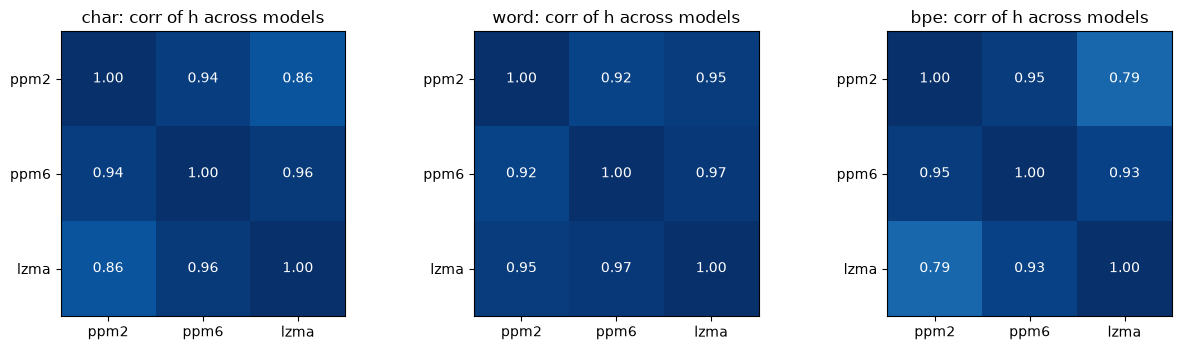

In [14]:
fig, axes = plt.subplots(1, len(LEVELS), figsize=(4.2 * len(LEVELS), 3.6))
for ax, lev in zip(np.atleast_1d(axes), LEVELS):
    M = LANG[[f'h_{lev}_{m}' for m in MODELS]].corr()
    M.index = M.columns = MODELS
    im = ax.imshow(M.values, vmin=0, vmax=1, cmap='Blues')
    for i in range(len(MODELS)):
        for j in range(len(MODELS)):
            ax.text(j, i, f'{M.values[i, j]:.2f}', ha='center', va='center', color='k' if M.values[i, j] < .7 else 'w')
    ax.set_xticks(range(len(MODELS)), MODELS); ax.set_yticks(range(len(MODELS)), MODELS); ax.set_title(f'{lev}: corr of h across models')
plt.tight_layout(); plt.savefig(RES / 'fig_model_consistency.png', dpi=150); plt.show()

> **Results.** Language rankings by entropy rate are very similar across models (r = 0.92–0.97 between PPM-6 and the others;
> lowest 0.79 for PPM-2 vs LZMA at the BPE level), in line with Koplenig et al. (their lowest median correlation 0.84).
> PPM-6 is the best model for 95 % of languages at the character level and 69–78 % at word and BPE level, so the
> "best-model" estimates are mostly PPM-6.

## 5. Statistical machinery (Koplenig et al., Sect. 2.6)

* **Controls** (cf. Sect. 2.6.1): endangerment status (AES), number of eBible translations of the language (logged;
  a proxy for literacy/resources and translation effects), writing-script dummies, absolute latitude, and the
  ethnographic controls community size, political hierarchy and agriculture (Enke-style). Missing control values are
  median-imputed with a missing-indicator so that the small samples are not reduced further.
* **Lasso** with a heteroskedasticity-robust plug-in penalty (Belloni, Chernozhukov & Hansen) selects controls.
  For regressions, *post-double-selection*: controls predicting the outcome ∪ controls predicting the predictor.
* **Moran's I** (Kelejian & Prucha) on residuals with inverse-distance weights — **geographic** (great-circle
  distance) and **phylogenetic** (number of branches between two languages in the Glottolog tree); I² ~ χ²(1).
* **Eigenvector spatial filtering**: if p < .05, eigenvectors of **M = (I − 11ᵀ/n) W (I − 11ᵀ/n)** are added one by one
  (largest eigenvalue first; for *both*, alternating geographic and phylogenetic, χ²(2)) until p ≥ .05.
* Correlations are reported as ρ_none, ρ_geo, ρ_phylo, ρ_both, exactly as in the paper.

In [15]:
def make_W_geo(df):
    lat, lon = df.lat.values, df.lon.values
    D = haversine(lat[:, None], lon[:, None], lat[None, :], lon[None, :]) + 1.0
    W = 1 / D; np.fill_diagonal(W, 0)
    return W / np.max(np.abs(np.linalg.eigvalsh((W + W.T) / 2)))

def make_W_phylo(df):
    paths = [(p.split('/') if p else ['iso:' + i]) + [i] for p, i in zip(df.path, df.index)]
    n = len(paths); D = np.zeros((n, n))
    for a in range(n):
        for b in range(a + 1, n):
            pa, pb = paths[a], paths[b]; k = 0
            while k < min(len(pa), len(pb)) and pa[k] == pb[k]:
                k += 1
            # different top-level families: distance = both depths + a constant "root" step
            D[a, b] = D[b, a] = (len(pa) - k) + (len(pb) - k) + (2 if k == 0 else 0)
    W = np.where(D > 0, 1 / np.where(D > 0, D, 1), 0)
    return W / np.max(np.abs(np.linalg.eigvalsh((W + W.T) / 2)))

def kp_moran(e, W):
    n = len(e); s2 = e @ e / n
    I = (e @ W @ e) / s2 / np.sqrt(np.trace((W.T + W) @ W))
    return I

def moran_p(e, Ws):
    stat = sum(kp_moran(e, W) ** 2 for W in Ws)
    return chi2.sf(stat, len(Ws))

def eigvecs(W):
    n = len(W); C = np.eye(n) - np.ones((n, n)) / n
    M = C @ ((W + W.T) / 2) @ C
    val, vec = np.linalg.eigh(M)
    order = np.argsort(val)[::-1]
    return vec[:, order]

def rlasso_select(y, X, c=1.1, iters=15):
    """Indices of columns of X selected by a plug-in (rigorous) lasso."""
    n, p = X.shape
    if p == 0: return []
    sd = X.std(0); ok = sd > 0
    Xs = np.zeros_like(X); Xs[:, ok] = (X[:, ok] - X[:, ok].mean(0)) / sd[ok]
    ys = y - y.mean()
    gamma = 0.1 / np.log(max(n, 3))
    lam = 2 * c * np.sqrt(n) * norm.ppf(1 - gamma / (2 * p))
    e = ys.copy(); sel = []
    for _ in range(iters):
        psi = np.sqrt(((Xs ** 2) * (e[:, None] ** 2)).mean(0)); psi[psi == 0] = 1e9
        fit = Lasso(alpha=lam / (2 * n), fit_intercept=False, max_iter=50000).fit(Xs / psi, ys)
        sel = list(np.flatnonzero(fit.coef_ != 0))
        e_new = ys - Xs[:, sel] @ np.linalg.lstsq(Xs[:, sel], ys, rcond=None)[0] if sel else ys
        if np.allclose(e_new, e): break
        e = e_new
    return sel

CTRL_NUM = ['aes', 'log_n_translations', 'abs_lat', 'community_size', 'jurisdiction', 'agriculture']

def control_matrix(df):
    X = pd.DataFrame(index=df.index)
    for c in CTRL_NUM:
        x = np.log(df['n_translations']) if c == 'log_n_translations' else df[c]
        miss = x.isna()
        X[c] = x.fillna(x.median() if x.notna().any() else 0)
        if miss.any() and not miss.all(): X[c + '_missing'] = miss.astype(float)
    X = X.join(pd.get_dummies(df.script_g, prefix='script', drop_first=True, dtype=float))
    return X.loc[:, X.std() > 0]

def residualize(y, X, Ws, max_ev=40):
    """OLS of y on lasso-selected X, then add eigenvectors until no residual autocorrelation (Koplenig Eq. 10)."""
    sel = rlasso_select(y, X.values)
    Z = np.column_stack([np.ones(len(y)), X.values[:, sel]])
    E = [eigvecs(W) for W in Ws]
    F = []; k = [0] * len(Ws); turn = 0
    while True:
        D = np.column_stack([Z] + F) if F else Z
        e = y - D @ np.linalg.lstsq(D, y, rcond=None)[0]
        cap = min(max_ev, max(1, len(y) // 3))     # never more filters than ~1/3 of the sample (and never more than exist)
        if not Ws or moran_p(e, Ws) >= 0.05 or len(F) >= cap:
            return e, len(F)
        j = turn % len(Ws); F.append(E[j][:, k[j]]); k[j] += 1; turn += 1

def partial_corrs(df, xcol, ycol):
    """rho_none, rho_geo, rho_phylo, rho_both between two language-level variables."""
    d = df.dropna(subset=[xcol, ycol, 'lat', 'lon']).copy()
    if len(d) < 8: return None
    X = control_matrix(d); Wg, Wp = make_W_geo(d), make_W_phylo(d)
    out = {'n': len(d)}
    out['rho_none'], out['p_none'] = stats.pearsonr(d[xcol], d[ycol])
    for name, Ws in [('geo', [Wg]), ('phylo', [Wp]), ('both', [Wg, Wp])]:
        ex, _ = residualize(d[xcol].values.astype(float), X, Ws)
        ey, _ = residualize(d[ycol].values.astype(float), X, Ws)
        out[f'rho_{name}'], out[f'p_{name}'] = stats.pearsonr(ex, ey)
    return out

## 6. Replicating the core finding in this sample: the complexity–efficiency trade-off
Koplenig et al. (Table 4): entropy rate and length are negatively correlated across languages, also after adjusting
for controls and geographic/phylogenetic autocorrelation.

In [16]:
rows = []
for hcol, lcol in [('h_char', 'L_char'), ('h_word', 'L_word'), ('h_bpe', 'L_char')]:
    r = partial_corrs(LANG, hcol, lcol)
    if r: rows.append(dict(pair=f'{hcol} vs {lcol}', **r))
tradeoff = pd.DataFrame(rows).set_index('pair')
tradeoff.round(3)

,n,rho_none,p_none,rho_geo,p_geo,rho_phylo,p_phylo,rho_both,p_both
pair,,,,,,,,,
h_char vs L_char,192,-0.793,0.0,-0.638,0.0,-0.654,0.0,-0.670,0.0
h_word vs L_word,192,-0.828,0.0,-0.795,0.0,-0.828,0.0,-0.793,0.0
h_bpe vs L_char,192,-0.795,0.0,-0.659,0.0,-0.673,0.0,-0.687,0.0


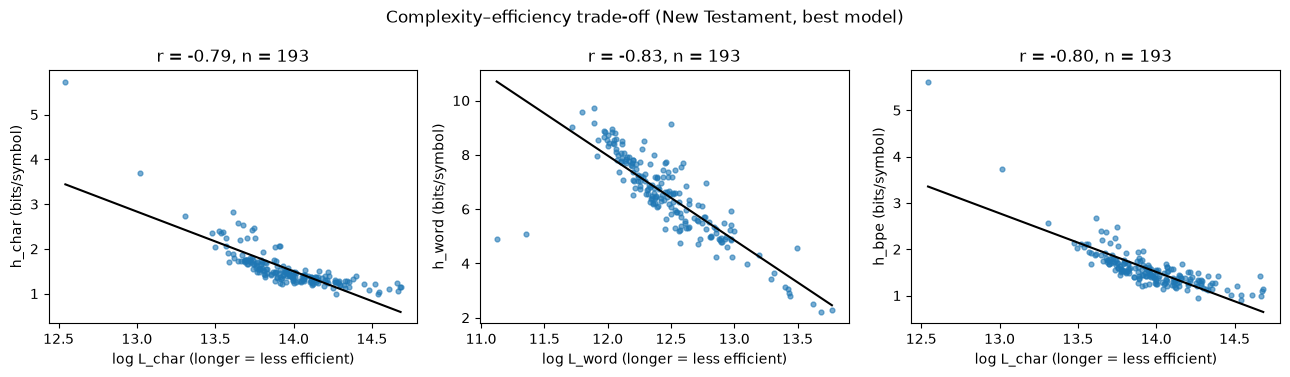

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (hcol, lcol) in zip(axes, [('h_char', 'L_char'), ('h_word', 'L_word'), ('h_bpe', 'L_char')]):
    d = LANG.dropna(subset=[hcol, lcol])
    ax.scatter(d[lcol], d[hcol], s=12, alpha=.6)
    b = np.polyfit(d[lcol], d[hcol], 1); xs = np.linspace(d[lcol].min(), d[lcol].max(), 10)
    ax.plot(xs, np.polyval(b, xs), 'k-')
    ax.set_xlabel(f'log {lcol} (longer = less efficient)'); ax.set_ylabel(f'{hcol} (bits/symbol)')
    ax.set_title(f'r = {np.corrcoef(d[lcol], d[hcol])[0,1]:.2f}, n = {len(d)}')
plt.suptitle('Complexity–efficiency trade-off (New Testament, best model)'); plt.tight_layout()
plt.savefig(RES / 'fig_tradeoff.png', dpi=150); plt.show()

> **Results.** **The trade-off replicates.** Entropy rate and length are strongly negatively correlated at all three levels
> (r = −0.79 to −0.83). After lasso-selected controls and geographic + phylogenetic eigenvector filtering the correlations
> remain large (ρ_both = −0.67 characters, −0.79 words, −0.69 BPE; all p < 10⁻²⁵). Languages that pack more information
> into each symbol use fewer symbols, exactly as Koplenig et al. report for their *BibleNT* and other corpora. The two points
> far to the upper left in the character panels are languages in non-alphabetic scripts; script dummies are among the controls.

## 7. Q1 — Complexity and efficiency vs market exposure and moral values

Three complementary analyses for each predictor × outcome:

1. **Partial correlations** ρ_none / ρ_geo / ρ_phylo / ρ_both (Koplenig Sect. 2.6.1).
2. **Regression** with post-double-selection lasso controls + eigenvector filters (geo + phylo), standard errors
   clustered by language family (Enke clusters by language sub-family).
3. **Multilevel models with multi-model inference** (Koplenig Sect. 2.6.2): outcome standardised; crossed random
   intercepts for family, macro-area and script; every subset of the fixed-effect controls is fitted by ML, and
   the predictor's effect is model-averaged with Akaike weights (Eqs. 13–16), with its relative importance.

Predictors are z-scored, so coefficients are "SD change in the outcome per SD of the predictor" for regressions on
standardised outcomes. A complexity–efficiency shift in the direction found by Koplenig for population size would show
up as **β > 0 for h** together with **β < 0 for L**.

In [18]:
PREDICTORS = ['market_sccs', 'market_any', 'moral_values', 'universalism_proxy', 'obedience', 'moralizing_god']
PREDICTORS += [c for c in LANG.columns if c.startswith('enke_')]
OUTCOMES = ['h_char', 'h_word', 'h_bpe', 'L_char', 'L_word', 'K_char']

def pds_regression(df, xcol, ycol):
    d = df.dropna(subset=[xcol, ycol, 'lat', 'lon']).copy()
    if len(d) < 10: return None
    y = z(d[ycol]).values; x = z(d[xcol]).values
    X = control_matrix(d)
    sel = sorted(set(rlasso_select(y, X.values)) | set(rlasso_select(x, X.values)))
    Ws = [make_W_geo(d), make_W_phylo(d)]
    Z = np.column_stack([np.ones(len(d)), x, X.values[:, sel]])
    E = [eigvecs(W) for W in Ws]; F = []; k = [0, 0]; t = 0
    while True:
        D = np.column_stack([Z] + F) if F else Z
        e = y - D @ np.linalg.lstsq(D, y, rcond=None)[0]
        if moran_p(e, Ws) >= .05 or len(F) >= min(40, max(1, len(y) // 3)): break
        j = t % 2; F.append(E[j][:, k[j]]); k[j] += 1; t += 1
    groups = pd.factorize(d.family)[0]
    fit = sm.OLS(y, D).fit(cov_type='cluster', cov_kwds={'groups': groups})
    return dict(n=len(d), beta=fit.params[1], se=fit.bse[1], p=fit.pvalues[1],
                controls=[X.columns[i] for i in sel], n_eigvec=len(F))

def mlm_fit(d, ycol, fixed):
    form = f'{ycol} ~ ' + ' + '.join(fixed)
    vcf = {'family': '0 + C(family)', 'area': '0 + C(macroarea)', 'script': '0 + C(script_g)'}
    md = smf.mixedlm(form, d, groups=np.ones(len(d)), vc_formula=vcf, re_formula='0')
    for method in ('lbfgs', 'powell', 'nm'):
        try:
            r = md.fit(reml=False, method=method, maxiter=400)
            if np.isfinite(r.llf): return r
        except Exception:
            pass
    return None

def multimodel(df, xcol, ycol, controls=('aes', 'log_n_translations', 'abs_lat', 'community_size', 'jurisdiction', 'agriculture')):
    d = df.dropna(subset=[xcol, ycol]).copy()
    if len(d) < 15: return None
    d['y'] = z(d[ycol]); d['x'] = z(d[xcol])
    d['log_n_translations'] = np.log(d.n_translations)
    ctrl = []
    for c in controls:
        if d[c].notna().mean() < 0.5: continue          # skip controls that are mostly missing in this sample
        d[c] = z(d[c].fillna(d[c].median())); ctrl.append(c)
    res = []
    for k in range(len(ctrl) + 1):
        for sub in itertools.combinations(ctrl, k):
            r = mlm_fit(d, 'y', ['x', *sub])
            if r is not None:
                res.append(dict(aic=r.aic, b=r.fe_params['x'], se=r.bse_fe['x']))
    if not res: return None
    R = pd.DataFrame(res); R['w'] = np.exp(-(R.aic - R.aic.min()) / 2); R.w /= R.w.sum()
    b = (R.w * R.b).sum()
    se = (R.w * np.sqrt(R.se ** 2 + (R.b - b) ** 2)).sum()      # Burnham & Anderson unconditional SE (Eq. 15)
    p = 2 * (1 - norm.cdf(abs(b / se)))
    return dict(n=len(d), beta_fma=b, se_fma=se, p_fma=p, n_models=len(R))

In [19]:
q1_rows = []
t0 = time.time()
for x in PREDICTORS:
    for yv in OUTCOMES:
        if LANG[[x, yv]].dropna().shape[0] < 10: continue
        pc = partial_corrs(LANG, x, yv) or {}
        rg = pds_regression(LANG, x, yv) or {}
        mm = multimodel(LANG, x, yv) or {}
        q1_rows.append(dict(predictor=x, outcome=yv, n=pc.get('n'),
                            rho_none=pc.get('rho_none'), p_none=pc.get('p_none'),
                            rho_both=pc.get('rho_both'), p_both=pc.get('p_both'),
                            rho_geo=pc.get('rho_geo'), rho_phylo=pc.get('rho_phylo'),
                            beta_pds=rg.get('beta'), se_pds=rg.get('se'), p_pds=rg.get('p'),
                            beta_fma=mm.get('beta_fma'), se_fma=mm.get('se_fma'), p_fma=mm.get('p_fma')))
    print(f'{x}: done ({time.time()-t0:.0f}s)')
Q1 = pd.DataFrame(q1_rows)
# Benjamini–Hochberg false-discovery-rate correction across all tests in the table
from statsmodels.stats.multitest import multipletests
for p in ['p_both', 'p_pds', 'p_fma']:
    ok = Q1[p].notna()
    Q1.loc[ok, p.replace('p_', 'q_')] = multipletests(Q1.loc[ok, p], method='fdr_bh')[1]
Q1.to_csv(RES / 'Q1_results.csv', index=False)
Q1.round(3)

market_sccs: done (7s)
market_any: done (15s)
moral_values: done (22s)
universalism_proxy: done (29s)
obedience: done (36s)
moralizing_god: done (44s)


,predictor,outcome,n,rho_none,p_none,rho_both,p_both,rho_geo,rho_phylo,beta_pds,se_pds,p_pds,beta_fma,se_fma,p_fma,q_both,q_pds,q_fma
0,market_sccs,h_char,39,0.471,0.003,0.355,0.026,0.355,0.471,0.471,0.150,0.002,-0.043,0.102,0.672,0.092,0.023,0.780
1,market_sccs,h_word,39,0.285,0.079,0.204,0.213,0.204,0.285,0.285,0.142,0.046,0.404,0.184,0.028,0.307,0.117,0.143
2,market_sccs,h_bpe,39,0.457,0.003,0.352,0.028,0.352,0.457,0.457,0.168,0.007,0.023,0.105,0.826,0.092,0.047,0.882
3,market_sccs,L_char,39,-0.532,0.000,-0.057,0.729,-0.057,-0.132,-0.148,0.138,0.283,-0.125,0.113,0.270,0.795,0.339,0.389
4,market_sccs,L_word,39,-0.404,0.011,-0.315,0.051,-0.315,-0.404,-0.404,0.130,0.002,-0.354,0.181,0.051,0.115,0.023,0.152
5,market_sccs,K_char,39,-0.262,0.107,-0.186,0.257,-0.186,-0.262,-0.262,0.202,0.194,-0.198,0.174,0.253,0.320,0.271,0.382
6,market_any,h_char,68,0.546,0.000,-0.060,0.630,-0.036,0.015,0.021,0.065,0.746,-0.004,0.058,0.944,0.708,0.767,0.944
7,market_any,h_word,68,0.195,0.110,0.239,0.049,0.253,0.239,0.332,0.177,0.060,0.247,0.117,0.035,0.115,0.131,0.152
8,market_any,h_bpe,68,0.524,0.000,0.025,0.840,-0.016,0.042,0.058,0.081,0.479,0.025,0.055,0.649,0.864,0.511,0.780
9,market_any,L_char,68,-0.563,0.000,-0.150,0.224,-0.140,-0.140,-0.143,0.082,0.081,-0.089,0.104,0.393,0.310,0.154,0.544


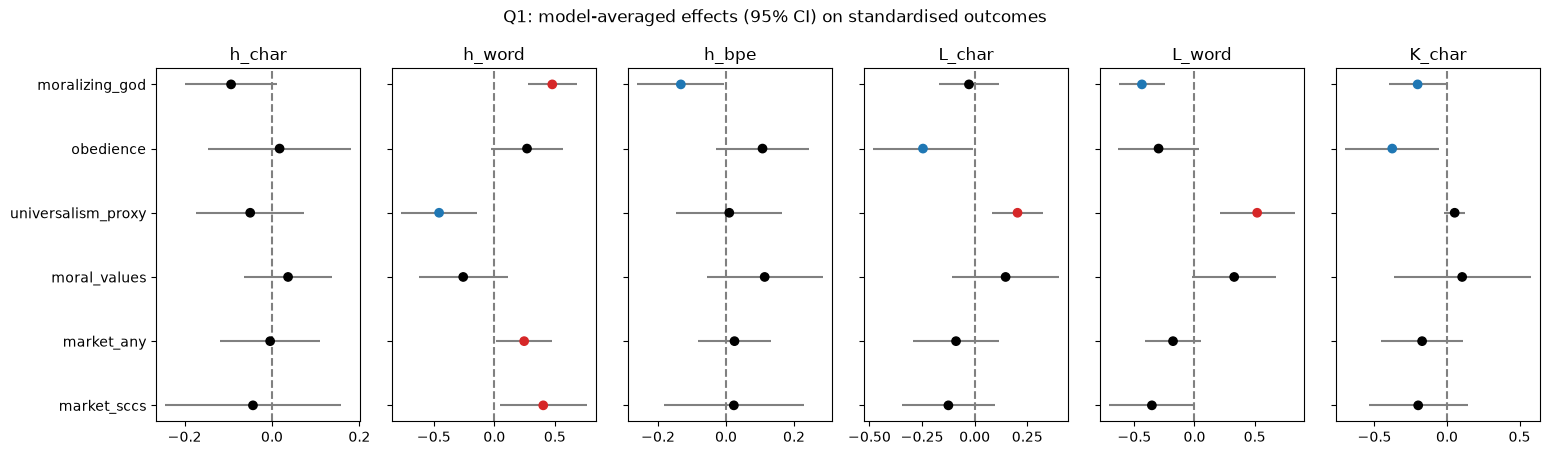

In [20]:
def coefplot(T, title, fname, est='beta_fma', se='se_fma', pcol='p_fma'):
    T = T.dropna(subset=[est])
    if T.empty:
        print('nothing to plot (sample too small)'); return
    preds = list(dict.fromkeys(T.predictor)); outs = list(dict.fromkeys(T.outcome))
    fig, axes = plt.subplots(1, len(outs), figsize=(2.6 * len(outs), 0.5 * len(preds) + 1.6), sharey=True)
    for ax, o in zip(np.atleast_1d(axes), outs):
        t = T[T.outcome == o].set_index('predictor').reindex(preds)
        yy = np.arange(len(preds))
        col = ['tab:red' if (p < .05 and b > 0) else 'tab:blue' if (p < .05 and b < 0) else 'k' for b, p in zip(t[est], t[pcol].fillna(1))]
        ax.errorbar(t[est], yy, xerr=1.96 * t[se], fmt='none', ecolor='grey')
        ax.scatter(t[est], yy, c=col, zorder=3)
        ax.axvline(0, ls='--', c='grey'); ax.set_title(o); ax.set_yticks(yy, preds)
    plt.suptitle(title); plt.tight_layout(); plt.savefig(RES / fname, dpi=150); plt.show()

coefplot(Q1, 'Q1: model-averaged effects (95% CI) on standardised outcomes', 'fig_Q1_coefficients.png')

> **Results.** Model-averaged multilevel estimates (red/blue = significant positive/negative):
> * **Market exposure** has no robust effect at character or BPE level once family, area and script random effects are
>   included, but a positive effect on **word-level entropy** (SCCS β = +0.40, p = .03; pooled β = +0.25, p = .035) and a
>   negative effect on **word count** (β = −0.35, p = .05; −0.18, p = .13). The partial correlations tell the same story
>   (ρ_both for L_word = −0.26 to −0.31). The SCCS index also keeps a character-level association in the partial
>   correlations (ρ_both = +0.36, p = .03) that disappears in the multilevel model. None survives FDR correction (q ≥ .14).
> * **Moralizing high gods** (largest sample, n = 119): +0.48 SD word-level entropy and −0.44 SD word count (both q < .001),
>   but slightly *lower* BPE entropy (β = −0.13, p = .04). Word-level measures strongly reflect morphology (languages with
>   long, rare word forms have high h_word and low L_word), so this mainly says such languages are more common among
>   societies with moralizing gods in this sample.
> * **Universalism proxy** (n = 26): −0.46 SD word entropy, +0.52 SD word count, +0.20 SD character count (q ≤ .03) —
>   the mirror image of the market and high-god pattern.
> * **Obedience** (n = 34): shorter texts and less total information (K_char β = −0.38, p = .02; q = .14).
> * **Child-taught moral values** (n = 30): no significant effect.

**Visual comparison**: languages split at the median of each market / morality measure.

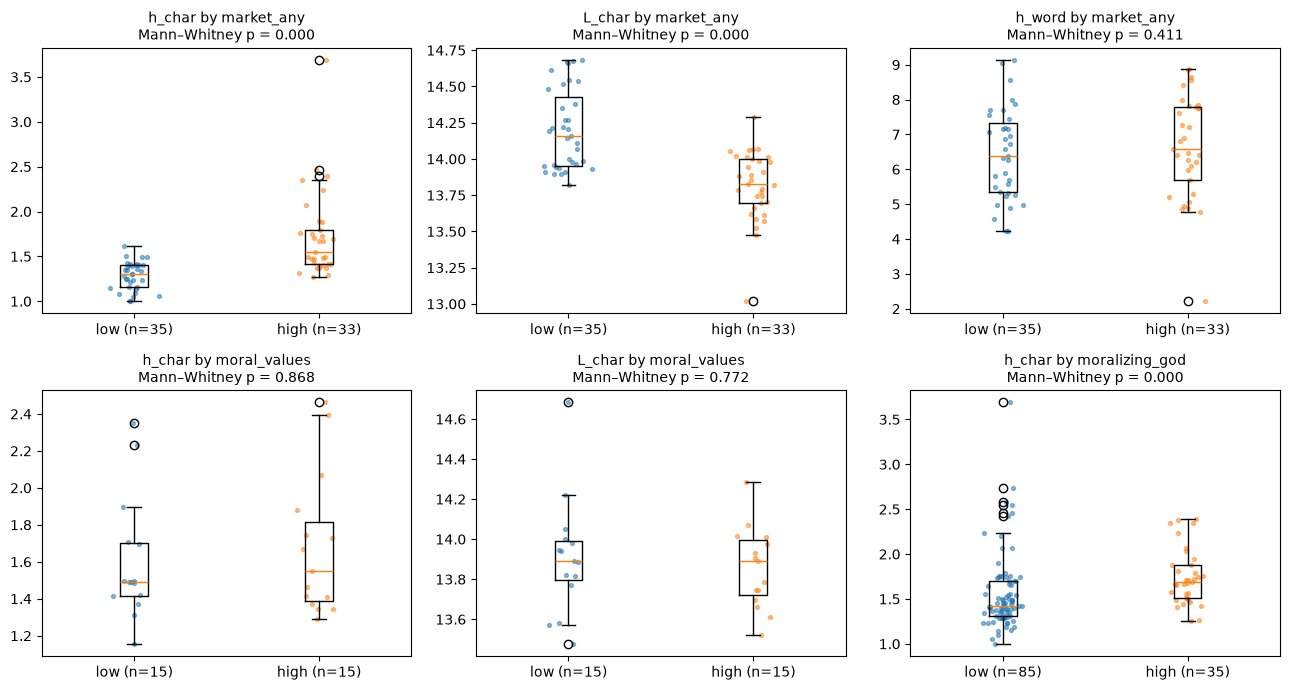

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (x, yv) in zip(axes.flat, [('market_any', 'h_char'), ('market_any', 'L_char'), ('market_any', 'h_word'),
                                   ('moral_values', 'h_char'), ('moral_values', 'L_char'), ('moralizing_god', 'h_char')]):
    d = LANG.dropna(subset=[x, yv])
    if len(d) < 5: ax.set_visible(False); continue
    hi = d[x] > d[x].median() if d[x].nunique() > 2 else d[x] > 0
    ax.boxplot([d.loc[~hi, yv], d.loc[hi, yv]])
    ax.set_xticks([1, 2], [f'low (n={(~hi).sum()})', f'high (n={hi.sum()})'])
    for k, grp in enumerate([d.loc[~hi, yv], d.loc[hi, yv]]):
        ax.scatter(np.random.normal(k + 1, .05, len(grp)), grp, s=8, alpha=.5)
    tstat, pv = stats.mannwhitneyu(d.loc[~hi, yv], d.loc[hi, yv])
    ax.set_title(f'{yv} by {x}\nMann–Whitney p = {pv:.3f}', fontsize=10)
plt.tight_layout(); plt.savefig(RES / 'fig_Q1_groups.png', dpi=150); plt.show()

> **Results.** Raw group differences are large for markets: languages of high-market societies have higher character-level
> entropy (median ≈ 1.55 vs 1.30 bits/char) and shorter texts (log length ≈ 13.8 vs 14.15, i.e. about 30 % fewer
> characters), both p < .001, and the same holds for moralizing gods. The adjusted analyses above show that most of this
> raw difference coincides with geography and language family (e.g. Eurasian and African languages vs Papuan and South
> American ones), so it should not be read as a direct effect of markets. Child-taught moral values show no difference.

### 7.1 Robustness: every language model separately
Koplenig et al. show their conclusions do not depend on the model. Same check for the market and morality effects
(partial correlation ρ_both with h estimated by each model separately).

In [22]:
rob = []
for x in ['market_any', 'market_sccs', 'moral_values', 'moralizing_god']:
    for lev in LEVELS:
        for m in MODELS:
            r = partial_corrs(LANG, x, f'h_{lev}_{m}')
            if r: rob.append(dict(predictor=x, level=lev, model=m, n=r['n'], rho_none=r['rho_none'], rho_both=r['rho_both'], p_both=r['p_both']))
ROB = pd.DataFrame(rob); ROB.to_csv(RES / 'Q1_robustness_models.csv', index=False)
ROB.pivot_table(index=['predictor', 'level'], columns='model', values='rho_both').round(2)

model                 lzma  ppm2  ppm6
predictor      level                  
market_any     bpe    0.04 -0.15 -0.05
               char   0.04 -0.04 -0.08
               word   0.23  0.20  0.22
market_sccs    bpe    0.36  0.18  0.29
               char   0.35  0.24  0.34
               word   0.19  0.11  0.22
moral_values   bpe    0.28  0.46  0.44
               char   0.05  0.47  0.35
               word  -0.25 -0.21 -0.20
moralizing_god bpe   -0.19 -0.43 -0.33
               char  -0.11 -0.30 -0.18
               word   0.46  0.45  0.42

> **Results.** Conclusions do not hinge on the model: the pooled market index's word-level association is ρ_both = 0.20–0.23
> under all three models; the SCCS index's character/BPE association is 0.18–0.36; moralizing gods are +0.42 to +0.46 at the
> word level and negative at the character/BPE level for every model. The moral-values association at character/BPE level
> is the exception: 0.35–0.47 with PPM but 0.05 with LZMA at the character level, so it is not robust.

### 7.2 Does market exposure moderate the trade-off?
Koplenig et al. argue that the social environment moves languages *along* the trade-off. If markets play a similar
role, the h–L slope itself should not change with markets (interaction ≈ 0) while the position does. We test the
interaction h ~ L × market with family-clustered SEs.

In [23]:
mod_rows = []
for x in ['market_any', 'market_sccs', 'moral_values', 'moralizing_god']:
    for hcol, lcol in [('h_char', 'L_char'), ('h_word', 'L_word')]:
        d = LANG.dropna(subset=[x, hcol, lcol]).copy()
        if len(d) < 15: continue
        d['hz'], d['Lz'], d['xz'] = z(d[hcol]), z(d[lcol]), z(d[x])
        f = smf.ols('hz ~ Lz * xz', d).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(d.family)[0]})
        mod_rows.append(dict(predictor=x, pair=f'{hcol}~{lcol}', n=len(d), slope_L=f.params['Lz'],
                             beta_x=f.params['xz'], p_x=f.pvalues['xz'], interaction=f.params['Lz:xz'], p_interaction=f.pvalues['Lz:xz']))
pd.DataFrame(mod_rows).round(3)

,predictor,pair,n,slope_L,beta_x,p_x,interaction,p_interaction
0,market_any,h_char~L_char,68,-0.801,-0.109,0.355,-0.422,0.000
1,market_any,h_word~L_word,68,-0.809,-0.063,0.386,0.119,0.516
2,market_sccs,h_char~L_char,39,-0.820,0.041,0.767,-0.361,0.000
3,market_sccs,h_word~L_word,39,-0.831,-0.043,0.706,0.301,0.281
4,moral_values,h_char~L_char,30,-0.822,0.286,0.059,-0.289,0.068
5,moral_values,h_word~L_word,30,-1.009,0.057,0.325,0.044,0.211
6,moralizing_god,h_char~L_char,120,-0.832,-0.078,0.208,-0.087,0.317
7,moralizing_god,h_word~L_word,120,-0.901,-0.003,0.958,-0.117,0.129


> **Results.** At a given text length, market exposure does not shift entropy (main effects p > .35). But the **interaction
> is strongly negative at the character level** (pooled −0.42, SCCS −0.36, both p < .001): the trade-off is *steeper* among
> market-exposed languages. In other words, markets do not move languages off the trade-off line; their languages are spread
> further along its complex-but-short end. A few high-market languages in non-Latin scripts with very high entropy contribute
> to this, so treat the interaction cautiously. No interaction at the word level, and none for the morality measures.

## 8. Q2 — Moral phrases versus the rest of the text

### 8.1 Which verses are "moral"?
Verses are tagged on the English World English Bible (public domain), then the **same verses** are compared in
every other language (the corpus is parallel, so content is held constant across languages).

Two tagging schemes:

* **Enke-style concept lists** (his Supplementary §1.2 is not open, so these are transparent lists built from the
  seed words he describes): *prosocial* (sharing, helping, giving, generosity vs selfishness/greed), *trust*
  (trust, honesty, faithfulness, deceit, lying), *universalism* (justice, fairness, equality, impartiality,
  strangers/neighbours), *particularism* (family, kin, obedience, tribe), *moral emotions* (guilt, shame, anger).
  `moral_any` = any of prosocial / trust / universalism / emotions. Edit the lists freely.
* **eMFD** (extended Moral Foundations Dictionary; Hopp et al. 2021): verses in the top quintile of mean moral
  probability.

### 8.2 How complexity and efficiency are measured for a set of verses
The **non-moral pool** = verses with no hit in any list and below-median eMFD score. In each of `Q2_SPLITS` random
splits, half of the pool is the **training text T**, the other half is where **matched controls** are drawn from:
for each moral verse a control verse from the same part of the NT (Gospels / Acts / Epistles / Revelation) with the
closest English length. Then, for a verse set S:

* conditional entropy rate **h(S | T) = [R(T + S) − R(T)] / chars(S)** — the same estimator as Eq. 5,
* length **L(S)** = characters of S in that language.

Per language: **Δh = log(h_moral / h_control)** (> 0: moral phrases are more complex) and **ΔL = log(L_moral / L_control)**
(> 0: moral phrases need more symbols, i.e. are less efficient, *relative to English*, because controls are matched on
English length).

In [24]:
LEX = {
 'prosocial': r"share[sd]?|sharing|help(s|ed|ing|er|ers)?|generous(ly)?|generosity|kind(ness|ly)?|charit\w*|alms|cooperat\w*|"
              r"selfish\w*|greed\w*|covet\w*|stingy|miser\w*|give to the poor|gave to the poor|feed the hungry",
 'trust':     r"trust(s|ed|ing|worthy)?|honest(y|ly)?|faithful(ly|ness)?|unfaithful\w*|reliab\w*|loyal\w*|deceiv\w*|deceit\w*|"
              r"betray\w*|lie to|lied|lying to|liar[s]?|falsehood|cheat\w*|false witness\w*|truthful\w*|promise[sd]?",
 'universalism': r"justice|unjust\w*|injustice|just(?!\s+(?:as|then|now|like|so))|fair(?!\s+weather)(ly|ness)?|equal(ly|ity)?|equity|"
                 r"impartial\w*|partiality|favoritism|stranger[s]?|foreigner[s]?|neighbou?r[s]?|every nation|enem(y|ies)",
 'particularism': r"famil(y|ies)|household[s]?|kin|kinsm[ae]n|relative[s]?|obe(y|ys|yed|ying|dience|dient)|disobe\w*|"
                  r"submit\w*|tribe[s]?|ancestor[s]?|tradition[s]?",
 'emotions':  r"guilt(y)?|shame(ful|d)?|ashamed|disgrace\w*|anger|angry|angered|wrath\w*|indignat\w*|furious|fury|rage|"
              r"remorse|repent\w*|regret\w*",
 'general_moral': r"sin(s|ned|ner|ners|ful)?|righteous\w*|unrighteous\w*|wicked\w*|evil|virtu\w*|transgress\w*|iniquit\w*|"
                  r"commandment[s]?|moral\w*|good works",
}
LEX_RE = {k: re.compile(r"\b(?:" + v + r")\b", re.I) for k, v in LEX.items()}

eng = [NT['eng'][i] for i in range(len(NT_REF))]
V = pd.DataFrame({'ref': NT_REF, 'text': eng})
V['book'] = V.ref.str.split().str[0]
GOSPELS, EPIST = {'MAT', 'MRK', 'LUK', 'JHN'}, None
V['part'] = np.select([V.book.isin(GOSPELS), V.book == 'ACT', V.book == 'REV'], ['gospels', 'acts', 'revelation'], 'epistles')
V['eng_len'] = V.text.str.len()
V['core'] = False; V.loc[CORE_IDX, 'core'] = True
for k, rx in LEX_RE.items():
    V[k] = V.text.map(lambda t: bool(rx.search(t)))
V['moral_any'] = V[['prosocial', 'trust', 'universalism', 'emotions']].any(axis=1)

emfd = pd.read_csv(RAW / 'emfd_scoring.csv').set_index('word')
emfd_p = emfd[['care_p', 'fairness_p', 'loyalty_p', 'authority_p', 'sanctity_p']].max(axis=1).to_dict()
def emfd_score(t):
    w = [emfd_p[x] for x in re.findall(r"[a-z']+", t.lower()) if x in emfd_p]
    return np.mean(w) if w else 0.0
V['emfd'] = V.text.map(emfd_score)
cv = V[V.core]
V['emfd_high'] = V.emfd >= cv.emfd.quantile(0.8)
V['pool'] = V.core & ~V[list(LEX)].any(axis=1) & (V.emfd < cv.emfd.median())

Q2_CATS = ['moral_any', 'prosocial', 'trust', 'universalism', 'particularism', 'emotions', 'emfd_high']
summary = pd.DataFrame({c: [int((V[c] & V.core).sum())] for c in Q2_CATS + ['general_moral']}, index=['core verses']).T
summary.loc['non-moral pool'] = int(V.pool.sum())
print(summary)
for c in ['prosocial', 'trust', 'universalism', 'emotions']:
    ex = V[V.core & V[c]].text.head(2).tolist()
    print(f'\n{c}:', *[' - ' + e[:110] for e in ex], sep='\n')

                core verses
moral_any               596
prosocial               118
trust                   217
universalism            127
particularism           149
emotions                151
emfd_high              1530
general_moral           592
non-moral pool         3406

prosocial:
 - “Be careful that you don’t do your charitable giving before men, to be seen by them, or else you have no rewar
 - When he came into Capernaum, a centurion came to him, asking him for help,

trust:
 - Simon the Zealot; and Judas Iscariot, who also betrayed him.
 - What was sown among the thorns, this is he who hears the word, but the cares of this age and the deceitfulness

universalism:
 - “You have heard that it was said, ‘You shall love your neighbor and hate your enemy.’
 - But I tell you, love your enemies, bless those who curse you, do good to those who hate you, and pray for thos

emotions:
 - Then Herod, when he saw that he was mocked by the wise men, was exceedingly angry, and sent out an

> **Results.** 596 core verses are tagged as moral by the Enke-style lists (118 prosocial, 217 trust, 127 universalism,
> 151 moral emotions; 149 particularism), and 1,530 by the eMFD top quintile; 3,406 verses form the non-moral pool.
> Keyword tagging is coarse: e.g. *betrayed* in a narrative ("Judas Iscariot, who also betrayed him") counts as a trust verse.
> That is why the eMFD tagging is kept as an independent check.

In [25]:
def matched_controls(cat_idx, cand_idx, rng):
    """For each target verse pick an unused candidate from the same NT part with the closest English length."""
    cand = V.loc[cand_idx, ['part', 'eng_len']].copy()
    used = set(); out = []
    for i in rng.permutation(cat_idx):
        c = cand[(cand.part == V.at[i, 'part']) & ~cand.index.isin(used)]
        if c.empty: c = cand[~cand.index.isin(used)]
        if c.empty: break
        j = (c.eng_len - V.at[i, 'eng_len']).abs().idxmin()
        used.add(j); out.append(j)
    return out

rng = np.random.default_rng(SEED)
DESIGN = []
pool_idx = V.index[V.pool].values
for s_ in range(Q2_SPLITS):
    perm = rng.permutation(pool_idx)
    train, ctrl_pool = np.sort(perm[: len(perm) // 2]), perm[len(perm) // 2:]
    split = {'train': train}
    for c in Q2_CATS:
        tgt = V.index[V[c] & V.core].values
        # a category larger than the control half-pool is subsampled so every moral verse has a match
        if len(tgt) > len(ctrl_pool): tgt = np.sort(rng.choice(tgt, len(ctrl_pool), replace=False))
        split[c] = (np.sort(tgt), np.sort(matched_controls(tgt, ctrl_pool, rng)))
    DESIGN.append(split)
print('train verses per split:', len(DESIGN[0]['train']))
print('English length check (moral vs control, chars):',
      {c: (int(V.loc[DESIGN[0][c][0], 'eng_len'].sum()), int(V.loc[DESIGN[0][c][1], 'eng_len'].sum())) for c in Q2_CATS})

train verses per split: 1703
English length check (moral vs control, chars): {'moral_any': (79051, 77307), 'prosocial': (15806, 15795), 'trust': (28643, 28596), 'universalism': (16333, 16282), 'particularism': (19657, 19650), 'emotions': (21078, 21091), 'emfd_high': (173600, 172633)}


> **Results.** Matched controls have almost exactly the English length of the moral verses (e.g. 79,051 vs 77,307 characters
> for all moral verses; within 0.3 % for each single category), so ΔL measures how much *more or less* each language expands
> moral content compared with English.

In [26]:
def q2_one(iso, lines, DESIGN, models=Q2_MODELS):
    have = usable_mask(lines)
    txt = lambda ids: [norm_text(lines[i].strip()) for i in ids if have[i]]
    rows = []
    for s_, split in enumerate(DESIGN):
        T = '\n'.join(txt(split['train'])) + '\n'
        Tb = T.encode('utf-8')
        RT = {m: compress_len(Tb, m) for m in models}
        for c in Q2_CATS:
            for kind, ids in zip(('moral', 'control'), split[c]):
                Sx = '\n'.join(txt(ids))
                for m in models:
                    K = compress_len(Tb + Sx.encode('utf-8'), m) - RT[m]
                    rows.append(dict(iso=iso, split=s_, cat=c, kind=kind, model=m, K=K, L=len(Sx),
                                     n=sum(have[i] for i in ids), h=K / max(len(Sx), 1)))
    return rows

import hashlib   # cache file is tied to the verse design: editing the lexicons or settings triggers recomputation
_sig = hashlib.md5(json.dumps([[sorted(map(int, sp['train']))] + [[sorted(map(int, sp[c][0])), sorted(map(int, sp[c][1]))] for c in Q2_CATS]
                               for sp in DESIGN] + [Q2_MODELS]).encode()).hexdigest()[:10]
Q2_FILE = RES / f'q2_raw_{_sig}.csv'
q2done = pd.read_csv(Q2_FILE) if Q2_FILE.exists() else pd.DataFrame(columns=['iso'])
todo = [i for i in chosen.index if i not in set(q2done.iso)]
print('languages to compute:', len(todo))
t0 = time.time()
for b in range(0, len(todo), 24):
    batch = todo[b:b + 24]
    res = run_parallel(q2_one, [(i, NT[i], DESIGN) for i in batch])
    q2done = pd.concat([q2done, pd.DataFrame([r for rr in res for r in rr])], ignore_index=True)
    q2done.to_csv(Q2_FILE, index=False)
    print(f'  {min(b + 24, len(todo))}/{len(todo)} languages, {time.time()-t0:.0f}s')

languages to compute: 0


In [27]:
q2 = pd.read_csv(Q2_FILE); q2 = q2[q2.iso.isin(chosen.index)]
# averages over splits; verse counts can differ slightly between moral/control if a translation lacks a verse,
# so lengths are per verse
agg = q2.groupby(['iso', 'cat', 'model', 'kind']).agg(h=('h', 'mean'), L=('L', 'mean'), n=('n', 'mean'), K=('K', 'mean')).unstack('kind')
D2 = pd.DataFrame({'dh': np.log(agg[('h', 'moral')] / agg[('h', 'control')]),
                   'dL': np.log((agg[('L', 'moral')] / agg[('n', 'moral')]) / (agg[('L', 'control')] / agg[('n', 'control')])),
                   'dK': np.log((agg[('K', 'moral')] / agg[('n', 'moral')]) / (agg[('K', 'control')] / agg[('n', 'control')])),
                   'h_moral': agg[('h', 'moral')], 'h_control': agg[('h', 'control')]}).reset_index()
D2.to_csv(RES / 'Q2_per_language.csv', index=False)
D2.groupby(['cat', 'model'])[['dh', 'dL', 'dK']].agg(['mean', 'std']).round(4)

dh              dL              dK        
                       mean     std    mean     std    mean     std
cat           model                                                
emfd_high     ppm2  -0.0151  0.0129  0.0736  0.0464  0.0584  0.0382
              ppm6   0.0096  0.0268  0.0736  0.0464  0.0832  0.0282
emotions      ppm2  -0.0206  0.0146  0.0891  0.0533  0.0686  0.0436
              ppm6  -0.0108  0.0248  0.0891  0.0533  0.0783  0.0372
moral_any     ppm2  -0.0106  0.0098  0.0771  0.0324  0.0665  0.0257
              ppm6   0.0009  0.0191  0.0771  0.0324  0.0780  0.0199
particularism ppm2  -0.0134  0.0106  0.0180  0.0264  0.0046  0.0239
              ppm6  -0.0025  0.0192  0.0180  0.0264  0.0155  0.0234
prosocial     ppm2   0.0026  0.0127  0.0355  0.0334  0.0382  0.0307
              ppm6   0.0494  0.0251  0.0355  0.0334  0.0850  0.0310
trust         ppm2  -0.0251  0.0119  0.0367  0.0326  0.0116  0.0268
              ppm6  -0.0203  0.0182  0.0367  0.0326  0.0165  0.0244
universalism  ppm2  -0.0183  0.0121  0.0499  0.0358  0.0316  0.0303
              ppm6   0.0191  0.0227  0.0499  0.0358  0.0690  0.0272

### 8.3 Are moral phrases more complex / less efficient than comparable non-moral phrases?
Test of mean Δh and ΔL across languages: a one-sample t-test, and a multilevel intercept-only model with crossed
random intercepts (family, macro-area, script) so that related languages do not count as independent evidence.
English is excluded from ΔL (it is the matching reference, ΔL ≈ 0 by construction).

In [28]:
D2m = D2.merge(LANG[['family', 'macroarea', 'script_g', 'lat', 'lon', 'path', 'aes', 'n_translations', 'abs_lat',
                     'community_size', 'jurisdiction', 'agriculture'] + PREDICTORS], left_on='iso', right_index=True)
lev_rows = []
for (c, m), d in D2m[D2m.iso != 'eng'].groupby(['cat', 'model']):
    row = dict(cat=c, model=m, n=len(d))
    for v in ['dh', 'dL']:
        t, p = stats.ttest_1samp(d[v], 0)
        r = mlm_fit(d.assign(y=d[v]), 'y', ['1'])
        row.update({f'mean_{v}': d[v].mean(), f'p_t_{v}': p,
                    f'mlm_{v}': r.fe_params['Intercept'] if r is not None else np.nan,
                    f'p_mlm_{v}': r.pvalues['Intercept'] if r is not None else np.nan,
                    f'share_pos_{v}': (d[v] > 0).mean()})
    row['corr_dh_dL'] = np.corrcoef(d.dh, d.dL)[0, 1]
    lev_rows.append(row)
Q2LEVEL = pd.DataFrame(lev_rows)
Q2LEVEL.to_csv(RES / 'Q2_levels.csv', index=False)
Q2LEVEL.round(4)

,cat,model,n,mean_dh,p_t_dh,mlm_dh,p_mlm_dh,share_pos_dh,mean_dL,p_t_dL,mlm_dL,p_mlm_dL,share_pos_dL,corr_dh_dL
0,emfd_high,ppm2,192,-0.0153,0.0000,-0.0138,0.0014,0.1458,0.0739,0.0,0.0682,0.0023,0.9844,-0.7185
1,emfd_high,ppm6,192,0.0093,0.0000,0.0063,0.5663,0.5938,0.0739,0.0,0.0682,0.0023,0.9844,-0.8348
2,emotions,ppm2,192,-0.0207,0.0000,-0.0197,0.0001,0.0833,0.0896,0.0,0.0917,0.0000,0.9792,-0.7386
3,emotions,ppm6,192,-0.0110,0.0000,-0.0153,0.0138,0.3958,0.0896,0.0,0.0917,0.0000,0.9792,-0.7820
4,moral_any,ppm2,192,-0.0107,0.0000,-0.0109,0.0000,0.1406,0.0773,0.0,0.0764,0.0000,1.0000,-0.7629
5,moral_any,ppm6,192,0.0007,0.6173,-0.0015,0.8209,0.5052,0.0773,0.0,0.0764,0.0000,1.0000,-0.8215
6,particularism,ppm2,192,-0.0135,0.0000,-0.0098,0.0176,0.0990,0.0180,0.0,0.0184,0.0147,0.7344,-0.4230
7,particularism,ppm6,192,-0.0026,0.0593,-0.0030,0.6928,0.4479,0.0180,0.0,0.0184,0.0147,0.7344,-0.5113
8,prosocial,ppm2,192,0.0024,0.0078,0.0015,0.7740,0.5781,0.0357,0.0,0.0296,0.1117,0.8802,-0.3889
9,prosocial,ppm6,192,0.0490,0.0000,0.0398,0.0002,0.9635,0.0357,0.0,0.0296,0.1117,0.8802,-0.4678


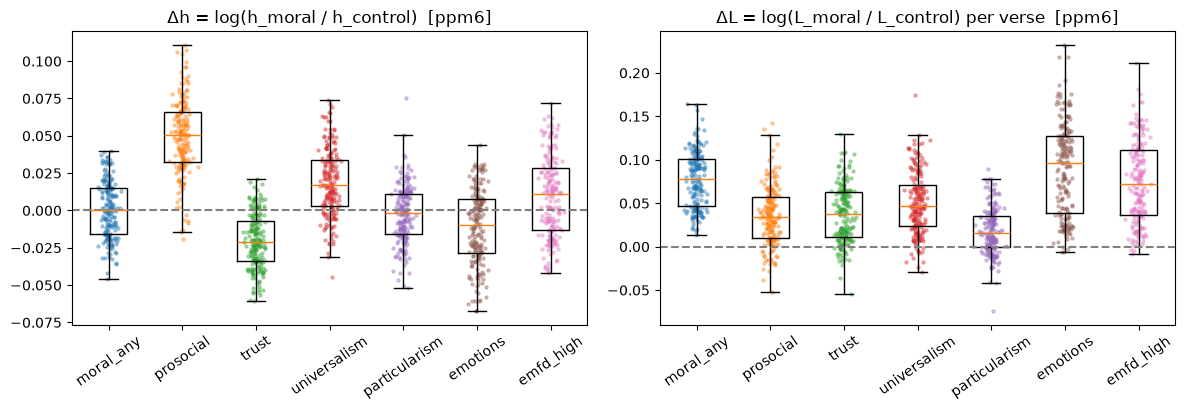

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
m0 = Q2_MODELS[0]
for ax, v, lab in zip(axes, ['dh', 'dL'], ['Δh = log(h_moral / h_control)', 'ΔL = log(L_moral / L_control) per verse']):
    d = D2m[(D2m.model == m0) & (D2m.iso != 'eng')]
    data = [d[d.cat == c][v].values for c in Q2_CATS]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, len(Q2_CATS) + 1), Q2_CATS)
    for k, arr in enumerate(data):
        ax.scatter(np.random.normal(k + 1, .06, len(arr)), arr, s=5, alpha=.35)
    ax.axhline(0, ls='--', c='grey'); ax.set_title(lab + f'  [{m0}]'); ax.tick_params(axis='x', rotation=35)
plt.tight_layout(); plt.savefig(RES / 'fig_Q2_levels.png', dpi=150); plt.show()

> **Results.** **Efficiency (ΔL):** moral verses need more characters than matched non-moral verses in essentially every
> language — for all moral verses in 100 % of the 192 languages, on average +7.7 % (multilevel p < 10⁻¹²). This holds for
> every category (emotions +9 %, universalism +5 %, trust +3.7 %, prosocial +3.6 %, particularism +1.8 %) and for the eMFD
> tagging (+7.4 %). Because controls are matched on English length, this means English (a language of a market society)
> expresses moral content unusually compactly; most languages need more words or longer words for moral concepts.
> 
> **Complexity (Δh):** on average moral verses are about as complex per character as the rest (all moral verses: +0.1 %,
> p = .82 with PPM-6; −1.1 % with PPM-2). The category picture is mixed: **trust** (−2.0 to −2.5 %) and **moral emotions**
> (−1.1 to −2.1 %) verses are *less* complex per character under both models; **prosocial** verses are more complex under
> PPM-6 (+4.9 %, 96 % of languages) but not under PPM-2; universalism flips sign between models. Differences in Δh are
> small (a few per cent) compared with the length differences.

### 8.4 Trade-off inside moral phrases, and relation to market exposure and moral values
* Is the complexity–efficiency trade-off also present for the moral-vs-control *differences* (corr(Δh, ΔL) < 0)?
  Same ρ_none … ρ_both machinery as in Section 6.
* Do languages of more market-exposed societies (or with stronger moral values) express moral content with relatively
  more/less complexity or length? Same three analyses as in Q1, with Δh and ΔL as outcomes.

In [30]:
tr_rows = []
for c in Q2_CATS:
    d = D2m[(D2m.cat == c) & (D2m.model == m0)].set_index('iso')
    r = partial_corrs(d, 'dh', 'dL')
    if r: tr_rows.append(dict(cat=c, **r))
pd.DataFrame(tr_rows).set_index('cat').round(3)

,n,rho_none,p_none,rho_geo,p_geo,rho_phylo,p_phylo,rho_both,p_both
cat,,,,,,,,,
moral_any,192,-0.822,0.0,-0.614,0.0,-0.678,0.0,-0.656,0.0
prosocial,192,-0.471,0.0,-0.412,0.0,-0.446,0.0,-0.451,0.0
trust,192,-0.673,0.0,-0.505,0.0,-0.552,0.0,-0.513,0.0
universalism,192,-0.652,0.0,-0.508,0.0,-0.554,0.0,-0.508,0.0
particularism,192,-0.518,0.0,-0.420,0.0,-0.417,0.0,-0.404,0.0
emotions,192,-0.784,0.0,-0.629,0.0,-0.650,0.0,-0.630,0.0
emfd_high,192,-0.836,0.0,-0.688,0.0,-0.722,0.0,-0.694,0.0


> **Results.** The complexity–efficiency trade-off reappears *inside* the moral domain: languages that spend relatively more
> characters on moral content spend fewer bits per character on it (corr(Δh, ΔL) = −0.82 for all moral verses; ρ_both = −0.66
> after controls and filtering; −0.40 to −0.69 for the single categories). The compensation is partial: total information
> for moral content is still ≈ 7–8 % higher than for matched controls (mean ΔK = +0.078 with PPM-6).

In [31]:
q2_rows = []
t0 = time.time()
for c in Q2_CATS:
    d = D2m[(D2m.cat == c) & (D2m.model == m0)].set_index('iso')
    for x in PREDICTORS:
        for yv in ['dh', 'dL']:
            if d[[x, yv]].dropna().shape[0] < 10: continue
            pc = partial_corrs(d, x, yv) or {}
            rg = pds_regression(d, x, yv) or {}
            mm = multimodel(d, x, yv) or {}
            q2_rows.append(dict(cat=c, predictor=x, outcome=yv, n=pc.get('n'),
                                rho_none=pc.get('rho_none'), p_none=pc.get('p_none'),
                                rho_both=pc.get('rho_both'), p_both=pc.get('p_both'),
                                beta_pds=rg.get('beta'), se_pds=rg.get('se'), p_pds=rg.get('p'),
                                beta_fma=mm.get('beta_fma'), se_fma=mm.get('se_fma'), p_fma=mm.get('p_fma')))
    print(f'{c}: done ({time.time()-t0:.0f}s)')
Q2 = pd.DataFrame(q2_rows)
for p in ['p_both', 'p_pds', 'p_fma']:
    ok = Q2[p].notna()
    Q2.loc[ok, p.replace('p_', 'q_')] = multipletests(Q2.loc[ok, p], method='fdr_bh')[1]
Q2.to_csv(RES / 'Q2_results.csv', index=False)
Q2.round(3)

moral_any: done (17s)
prosocial: done (34s)
trust: done (51s)
universalism: done (67s)
particularism: done (82s)
emotions: done (100s)
emfd_high: done (117s)


,cat,predictor,outcome,n,rho_none,p_none,rho_both,p_both,beta_pds,se_pds,p_pds,beta_fma,se_fma,p_fma,q_both,q_pds,q_fma
0,moral_any,market_sccs,dh,39,0.636,0.000,0.223,0.172,0.315,0.115,0.006,0.320,0.141,0.023,0.426,0.035,0.120
1,moral_any,market_sccs,dL,39,-0.510,0.001,0.023,0.890,-0.116,0.100,0.245,-0.112,0.152,0.461,0.923,0.447,0.718
2,moral_any,market_any,dh,68,0.650,0.000,0.300,0.013,0.298,0.098,0.002,0.295,0.107,0.006,0.077,0.020,0.051
3,moral_any,market_any,dL,68,-0.536,0.000,-0.118,0.339,-0.121,0.074,0.102,-0.139,0.118,0.239,0.627,0.272,0.478
4,moral_any,moral_values,dh,30,-0.091,0.633,-0.293,0.116,-0.217,0.132,0.101,-0.260,0.134,0.053,0.326,0.272,0.174
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,emfd_high,universalism_proxy,dL,26,0.360,0.071,0.492,0.011,0.336,0.106,0.002,0.330,0.132,0.012,0.076,0.017,0.084
80,emfd_high,obedience,dh,34,0.436,0.010,0.243,0.166,0.228,0.155,0.139,0.265,0.127,0.038,0.421,0.308,0.150
81,emfd_high,obedience,dL,34,-0.478,0.004,-0.276,0.114,-0.237,0.100,0.018,-0.237,0.119,0.046,0.326,0.079,0.161
82,emfd_high,moralizing_god,dh,119,0.436,0.000,0.225,0.014,0.149,0.113,0.187,0.178,0.081,0.028,0.077,0.384,0.129


**Robustness of the Q2 market/morality relations.** (a) Each language model separately; (b) additionally controlling
for the language's overall entropy rate and text length (h_char, L_char), so that a relation cannot simply reflect
languages being generally more complex or more compact; (c) the eMFD-based tagging instead of the keyword lists.

In [32]:
rb = []
for c in ['moral_any', 'emfd_high']:
    for m in Q2_MODELS:
        d = D2m[(D2m.cat == c) & (D2m.model == m)].set_index('iso').join(LANG[['h_char', 'L_char']])
        for x in ['market_sccs', 'market_any', 'moral_values', 'universalism_proxy', 'obedience', 'moralizing_god']:
            for yv in ['dh', 'dL']:
                dd = d.dropna(subset=[x, yv, 'h_char', 'L_char'])
                if len(dd) < 10: continue
                pc = partial_corrs(d, x, yv) or {}
                f = smf.ols(f'{yv} ~ {x} + h_char + L_char', dd.assign(**{x: z(dd[x])})).fit(
                    cov_type='cluster', cov_kwds={'groups': pd.factorize(dd.family)[0]})
                rb.append(dict(cat=c, model=m, predictor=x, outcome=yv, n=len(dd), rho_none=pc.get('rho_none'),
                               rho_both=pc.get('rho_both'), p_both=pc.get('p_both'),
                               b_ctrl_h_L=f.params[x], p_ctrl_h_L=f.pvalues[x]))
Q2ROB = pd.DataFrame(rb); Q2ROB.to_csv(RES / 'Q2_robustness.csv', index=False)
Q2ROB.pivot_table(index=['predictor', 'outcome'], columns=['cat', 'model'], values='rho_both').round(2)

cat                        emfd_high       moral_any      
model                           ppm2  ppm6      ppm2  ppm6
predictor          outcome                                
market_any         dL          -0.12 -0.12     -0.12 -0.12
                   dh           0.03  0.20      0.18  0.30
market_sccs        dL           0.02  0.02      0.02  0.02
                   dh          -0.05  0.10      0.04  0.22
moral_values       dL           0.22  0.22      0.04  0.04
                   dh          -0.36 -0.22     -0.29 -0.29
moralizing_god     dL          -0.06 -0.06     -0.04 -0.04
                   dh           0.02  0.23     -0.03  0.20
obedience          dL          -0.28 -0.28     -0.09 -0.09
                   dh           0.07  0.24      0.16  0.31
universalism_proxy dL           0.49  0.49      0.07  0.07
                   dh          -0.43 -0.50     -0.41 -0.56

> **Results.** **Market exposure → Δh** for all moral verses: ρ_both = +0.30 (PPM-6) and +0.18 (PPM-2) for the pooled index;
> +0.22 and +0.04 for the SCCS index; with eMFD tagging +0.20 and +0.03. So the positive relation is consistent with PPM-6 but
> weak with PPM-2 — suggestive, not robust. Market exposure is not related to ΔL after adjustment (ρ_both ≈ −0.12).
> The **universalism proxy → Δh** relation is the most robust one here (ρ_both = −0.41 to −0.56 across both models and both
> taggings). For the version that also controls for each language's overall entropy and length, see the columns
> `b_ctrl_h_L` / `p_ctrl_h_L` in `results/Q2_robustness.csv`.

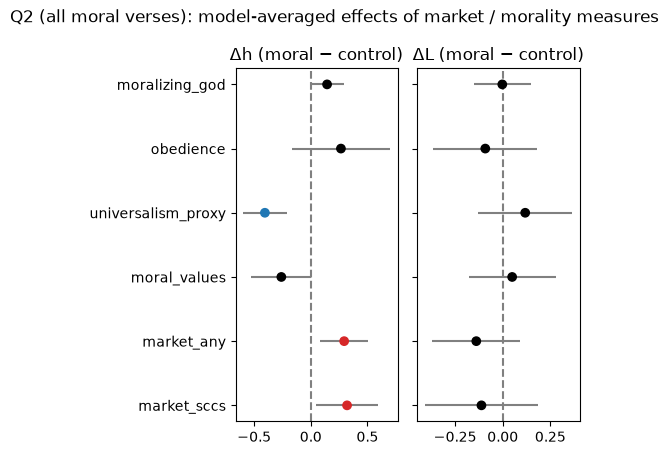

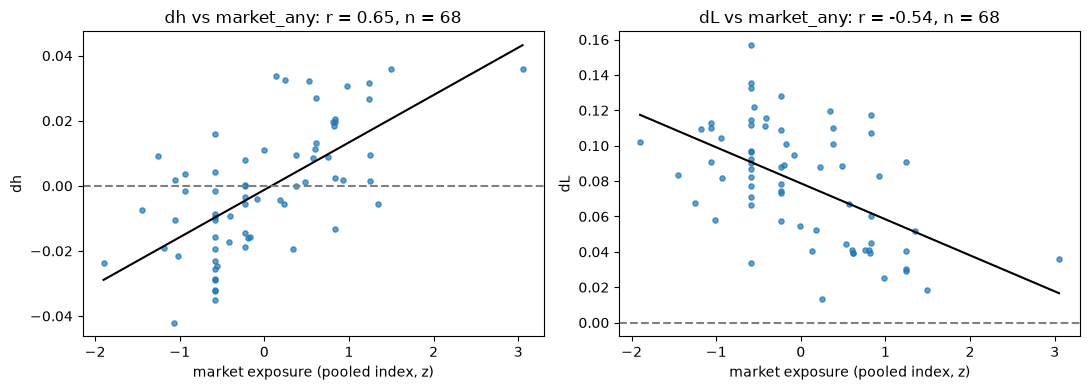

In [33]:
T = Q2[Q2.cat == 'moral_any'].copy(); T['outcome'] = T.outcome.map({'dh': 'Δh (moral − control)', 'dL': 'ΔL (moral − control)'})
coefplot(T, 'Q2 (all moral verses): model-averaged effects of market / morality measures', 'fig_Q2_coefficients.png')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
d = D2m[(D2m.cat == 'moral_any') & (D2m.model == m0)]
for ax, yv in zip(axes, ['dh', 'dL']):
    dd = d.dropna(subset=['market_any', yv])
    ax.scatter(dd.market_any, dd[yv], s=14, alpha=.7)
    if len(dd) > 3:
        b = np.polyfit(dd.market_any, dd[yv], 1); xs = np.linspace(dd.market_any.min(), dd.market_any.max(), 10)
        ax.plot(xs, np.polyval(b, xs), 'k-')
        ax.set_title(f'{yv} vs market_any: r = {np.corrcoef(dd.market_any, dd[yv])[0,1]:.2f}, n = {len(dd)}')
    ax.set_xlabel('market exposure (pooled index, z)'); ax.set_ylabel(yv); ax.axhline(0, ls='--', c='grey')
plt.tight_layout(); plt.savefig(RES / 'fig_Q2_market.png', dpi=150); plt.show()

> **Results.** For all moral verses, the multilevel model-averaged effects are:
> * **Market exposure → Δh positive**: pooled index β = +0.29 (p = .006, q = .05; ρ_both = +0.30, p = .013), SCCS index
>   β = +0.32 (p = .02, q = .12). In languages of market-exposed societies moral passages are relatively *more*
>   information-dense per character than other passages. One reading consistent with Enke: where markets (and universalist,
>   impersonal morality) matter, moral concepts are lexicalised as compact words rather than paraphrased. The raw link
>   with ΔL (r = −0.54: less expansion of moral content) does not survive adjustment.
> * **Universalism proxy → Δh negative** (β = −0.41, q < .001, n = 26), and child-taught moral values point the same way
>   (β = −0.26, p = .053) — opposite to markets, although in Enke's data markets and universalism go together. The SCCS
>   child-training codes evidently capture something different from Enke's folklore-based universalism.
> * **Moralizing gods → Δh**: β = +0.14 (p = .054; ρ_both = +0.20, p = .03).
> * Obedience: no significant effect. No predictor has a robust effect on ΔL.
> The scatter plot shows the raw market–Δh relation (r ≈ 0.65), which is partly regional; the adjusted estimates above are
> the ones to rely on.

## 9. Optional: use Koplenig et al.'s published entropy estimates
If you downloaded their data from OSF (https://osf.io/xdwjc/), put the file(s) with per-document entropy estimates in
`data/koplenig/`. This cell looks for a table with an ISO-639-3 column and entropy/length columns, keeps the
*BibleNT* rows if a corpus column exists, averages per language, and repeats the Q1 partial correlations with their
estimates (which use more models — PAQ, LSTM, Transformers — and many more corpora). Set `KOP_COLUMNS` if the
automatic detection picks the wrong columns.

In [34]:
KOP_COLUMNS = {}   # e.g. {'iso': 'iso', 'corpus': 'corpus', 'h': 'h_best_char', 'L': 'L_char'}

def load_koplenig():
    files = [p for p in KOP_DIR.rglob('*') if p.suffix.lower() in ('.csv', '.dta', '.tsv', '.txt', '.xlsx')]
    tables = []
    for f in files:
        try:
            df = (pd.read_stata(f, convert_categoricals=False) if f.suffix.lower() == '.dta' else
                  pd.read_excel(f) if f.suffix.lower() == '.xlsx' else pd.read_csv(f, sep=None, engine='python'))
        except Exception as ex:
            print('  could not read', f.name, ex); continue
        cols = df.columns
        C = {'iso': _find_col(cols, [r'^iso', r'iso_?639', r'^language$', r'^lang$']),
             'corpus': _find_col(cols, [r'^corpus', r'collection']),
             'h': _find_col(cols, [r'^h_?best', r'entropy', r'^h_']),
             'L': _find_col(cols, [r'^l_?(char|word)', r'length', r'^L$'])}
        C.update(KOP_COLUMNS)
        if C['iso'] and (C['h'] or C['L']):
            tables.append((f, df, C))
    return tables

kop_tables = load_koplenig() if any(KOP_DIR.iterdir()) else []
if not kop_tables:
    print('No Koplenig et al. data in data/koplenig/ -> skipping (all analyses above use our own estimates).')
for f, df, C in kop_tables:
    print('using', f.name, C)
    if C['corpus']:
        nt = df[df[C['corpus']].astype(str).str.contains('NT', case=False)]
        df = nt if len(nt) else df
    kl = df.groupby(df[C['iso']].astype(str).str.lower()).mean(numeric_only=True)
    kl = kl.join(meta, how='inner').join(cult, how='left')
    for x in ['market_sccs', 'market_any', 'moral_values', 'moralizing_god']:
        for yv in [c for c in (C['h'], C['L']) if c]:
            r = partial_corrs(kl, x, yv)
            if r: print(f'  {x} vs {yv}: n={r["n"]}, rho_none={r["rho_none"]:.3f}, rho_both={r["rho_both"]:.3f} (p={r["p_both"]:.3f})')
    # agreement between our estimates and theirs
    if C['h']:
        both = kl[[C['h']]].join(LANG[['h_char', 'h_word', 'h_bpe']], how='inner')
        print('  correlation of their h with ours:\n', both.corr().iloc[0, 1:].round(3))

No Koplenig et al. data in data/koplenig/ -> skipping (all analyses above use our own estimates).


## 10. Summary
Generated from the result tables above (FMA = multilevel model-averaged estimate; ρ_both = partial correlation
adjusted for controls and geographic + phylogenetic autocorrelation; q = Benjamini–Hochberg FDR-adjusted p).

The written conclusions follow the generated summary.

In [35]:
def fmt(r):
    return (f"β_FMA = {r.beta_fma:+.2f} (p = {r.p_fma:.3f}, q = {r.q_fma:.2f}); ρ_both = {r.rho_both:+.2f} (p = {r.p_both:.3f}); n = {int(r.n)}"
            if pd.notna(r.beta_fma) else f"ρ_both = {r.rho_both:+.2f} (p = {r.p_both:.3f}); n = {int(r.n)}")

lines = ['### Sample', f'- {len(LANG)} languages with a New Testament; {LANG.family.nunique()} families; '
         f'market data for {LANG.market_any.notna().sum()} (SCCS core: {LANG.market_sccs.notna().sum()}), child-value data for '
         f'{LANG.moral_values.notna().sum()}, high-god data for {LANG.moralizing_god.notna().sum()}.']
lines.append('\n### Trade-off (replication of Koplenig et al.)')
for p, r in tradeoff.iterrows():
    lines.append(f'- {p}: ρ_none = {r.rho_none:+.2f}, ρ_both = {r.rho_both:+.2f} (p = {r.p_both:.3g}), n = {int(r.n)}')
lines.append('\n### Q1: complexity (h) and efficiency (L) vs markets and morality')
for _, r in Q1.iterrows():
    star = ' **(q<.05)**' if (pd.notna(r.get('q_fma')) and r.q_fma < .05) else ''
    lines.append(f'- {r.predictor} → {r.outcome}: {fmt(r)}{star}')
lines.append('\n### Q2: moral vs matched non-moral verses (positive Δh = moral phrases more complex; positive ΔL = more characters)')
for _, r in Q2LEVEL[Q2LEVEL.model == m0].iterrows():
    lines.append(f"- {r['cat']}: mean Δh = {r.mean_dh:+.4f} (multilevel p = {r.p_mlm_dh:.3g}, {100*r.share_pos_dh:.0f}% of languages > 0); "
                 f'mean ΔL = {r.mean_dL:+.4f} (p = {r.p_mlm_dL:.3g}); corr(Δh, ΔL) = {r.corr_dh_dL:+.2f}')
lines.append('\n### Q2: relation of Δh / ΔL to markets and morality (all moral verses)')
for _, r in Q2[Q2.cat == 'moral_any'].iterrows():
    star = ' **(q<.05)**' if (pd.notna(r.get('q_fma')) and r.q_fma < .05) else ''
    lines.append(f'- {r.predictor} → {r.outcome}: {fmt(r)}{star}')
report = '\n'.join(lines)
(RES / 'summary.md').write_text(report, encoding='utf-8')
from IPython.display import Markdown, display
display(Markdown(report))

### Sample
- 193 languages with a New Testament; 54 families; market data for 68 (SCCS core: 39), child-value data for 30, high-god data for 120.

### Trade-off (replication of Koplenig et al.)
- h_char vs L_char: ρ_none = -0.79, ρ_both = -0.67 (p = 2.49e-26), n = 192
- h_word vs L_word: ρ_none = -0.83, ρ_both = -0.79 (p = 7.6e-43), n = 192
- h_bpe vs L_char: ρ_none = -0.80, ρ_both = -0.69 (p = 3.78e-28), n = 192

### Q1: complexity (h) and efficiency (L) vs markets and morality
- market_sccs → h_char: β_FMA = -0.04 (p = 0.672, q = 0.78); ρ_both = +0.36 (p = 0.026); n = 39
- market_sccs → h_word: β_FMA = +0.40 (p = 0.028, q = 0.14); ρ_both = +0.20 (p = 0.213); n = 39
- market_sccs → h_bpe: β_FMA = +0.02 (p = 0.826, q = 0.88); ρ_both = +0.35 (p = 0.028); n = 39
- market_sccs → L_char: β_FMA = -0.12 (p = 0.270, q = 0.39); ρ_both = -0.06 (p = 0.729); n = 39
- market_sccs → L_word: β_FMA = -0.35 (p = 0.051, q = 0.15); ρ_both = -0.31 (p = 0.051); n = 39
- market_sccs → K_char: β_FMA = -0.20 (p = 0.253, q = 0.38); ρ_both = -0.19 (p = 0.257); n = 39
- market_any → h_char: β_FMA = -0.00 (p = 0.944, q = 0.94); ρ_both = -0.06 (p = 0.630); n = 68
- market_any → h_word: β_FMA = +0.25 (p = 0.035, q = 0.15); ρ_both = +0.24 (p = 0.049); n = 68
- market_any → h_bpe: β_FMA = +0.02 (p = 0.649, q = 0.78); ρ_both = +0.03 (p = 0.840); n = 68
- market_any → L_char: β_FMA = -0.09 (p = 0.393, q = 0.54); ρ_both = -0.15 (p = 0.224); n = 68
- market_any → L_word: β_FMA = -0.18 (p = 0.134, q = 0.27); ρ_both = -0.26 (p = 0.033); n = 68
- market_any → K_char: β_FMA = -0.17 (p = 0.236, q = 0.38); ρ_both = -0.14 (p = 0.258); n = 68
- moral_values → h_char: β_FMA = +0.04 (p = 0.471, q = 0.61); ρ_both = +0.26 (p = 0.162); n = 30
- moral_values → h_word: β_FMA = -0.26 (p = 0.170, q = 0.31); ρ_both = -0.24 (p = 0.198); n = 30
- moral_values → h_bpe: β_FMA = +0.11 (p = 0.192, q = 0.33); ρ_both = +0.31 (p = 0.100); n = 30
- moral_values → L_char: β_FMA = +0.15 (p = 0.254, q = 0.38); ρ_both = -0.01 (p = 0.966); n = 30
- moral_values → L_word: β_FMA = +0.33 (p = 0.064, q = 0.18); ρ_both = +0.32 (p = 0.087); n = 30
- moral_values → K_char: β_FMA = +0.10 (p = 0.664, q = 0.78); ρ_both = +0.27 (p = 0.145); n = 30
- universalism_proxy → h_char: β_FMA = -0.05 (p = 0.430, q = 0.57); ρ_both = +0.21 (p = 0.308); n = 26
- universalism_proxy → h_word: β_FMA = -0.46 (p = 0.004, q = 0.03); ρ_both = -0.47 (p = 0.015); n = 26 **(q<.05)**
- universalism_proxy → h_bpe: β_FMA = +0.01 (p = 0.903, q = 0.93); ρ_both = +0.19 (p = 0.357); n = 26
- universalism_proxy → L_char: β_FMA = +0.20 (p = 0.001, q = 0.01); ρ_both = +0.27 (p = 0.180); n = 26 **(q<.05)**
- universalism_proxy → L_word: β_FMA = +0.52 (p = 0.001, q = 0.01); ρ_both = +0.56 (p = 0.003); n = 26 **(q<.05)**
- universalism_proxy → K_char: β_FMA = +0.05 (p = 0.150, q = 0.28); ρ_both = +0.49 (p = 0.011); n = 26
- obedience → h_char: β_FMA = +0.02 (p = 0.833, q = 0.88); ρ_both = +0.34 (p = 0.046); n = 34
- obedience → h_word: β_FMA = +0.27 (p = 0.077, q = 0.19); ρ_both = +0.23 (p = 0.200); n = 34
- obedience → h_bpe: β_FMA = +0.11 (p = 0.125, q = 0.26); ρ_both = +0.35 (p = 0.039); n = 34
- obedience → L_char: β_FMA = -0.25 (p = 0.042, q = 0.15); ρ_both = -0.29 (p = 0.100); n = 34
- obedience → L_word: β_FMA = -0.30 (p = 0.085, q = 0.19); ρ_both = -0.41 (p = 0.015); n = 34
- obedience → K_char: β_FMA = -0.38 (p = 0.023, q = 0.14); ρ_both = -0.43 (p = 0.011); n = 34
- moralizing_god → h_char: β_FMA = -0.09 (p = 0.081, q = 0.19); ρ_both = -0.11 (p = 0.239); n = 119
- moralizing_god → h_word: β_FMA = +0.48 (p = 0.000, q = 0.00); ρ_both = +0.46 (p = 0.000); n = 119 **(q<.05)**
- moralizing_god → h_bpe: β_FMA = -0.13 (p = 0.043, q = 0.15); ρ_both = -0.22 (p = 0.019); n = 119
- moralizing_god → L_char: β_FMA = -0.03 (p = 0.712, q = 0.80); ρ_both = -0.03 (p = 0.756); n = 119
- moralizing_god → L_word: β_FMA = -0.44 (p = 0.000, q = 0.00); ρ_both = -0.37 (p = 0.000); n = 119 **(q<.05)**
- moralizing_god → K_char: β_FMA = -0.20 (p = 0.046, q = 0.15); ρ_both = -0.20 (p = 0.026); n = 119

### Q2: moral vs matched non-moral verses (positive Δh = moral phrases more complex; positive ΔL = more characters)
- emfd_high: mean Δh = +0.0093 (multilevel p = 0.566, 59% of languages > 0); mean ΔL = +0.0739 (p = 0.00231); corr(Δh, ΔL) = -0.83
- emotions: mean Δh = -0.0110 (multilevel p = 0.0138, 40% of languages > 0); mean ΔL = +0.0896 (p = 1.66e-10); corr(Δh, ΔL) = -0.78
- moral_any: mean Δh = +0.0007 (multilevel p = 0.821, 51% of languages > 0); mean ΔL = +0.0773 (p = 3.74e-13); corr(Δh, ΔL) = -0.82
- particularism: mean Δh = -0.0026 (multilevel p = 0.693, 45% of languages > 0); mean ΔL = +0.0180 (p = 0.0147); corr(Δh, ΔL) = -0.51
- prosocial: mean Δh = +0.0490 (multilevel p = 0.000178, 96% of languages > 0); mean ΔL = +0.0357 (p = 0.112); corr(Δh, ΔL) = -0.47
- trust: mean Δh = -0.0204 (multilevel p = 0.000151, 17% of languages > 0); mean ΔL = +0.0369 (p = 5.25e-05); corr(Δh, ΔL) = -0.67
- universalism: mean Δh = +0.0188 (multilevel p = 0.102, 80% of languages > 0); mean ΔL = +0.0501 (p = 1.48e-05); corr(Δh, ΔL) = -0.65

### Q2: relation of Δh / ΔL to markets and morality (all moral verses)
- market_sccs → dh: β_FMA = +0.32 (p = 0.023, q = 0.12); ρ_both = +0.22 (p = 0.172); n = 39
- market_sccs → dL: β_FMA = -0.11 (p = 0.461, q = 0.72); ρ_both = +0.02 (p = 0.890); n = 39
- market_any → dh: β_FMA = +0.29 (p = 0.006, q = 0.05); ρ_both = +0.30 (p = 0.013); n = 68
- market_any → dL: β_FMA = -0.14 (p = 0.239, q = 0.48); ρ_both = -0.12 (p = 0.339); n = 68
- moral_values → dh: β_FMA = -0.26 (p = 0.053, q = 0.17); ρ_both = -0.29 (p = 0.116); n = 30
- moral_values → dL: β_FMA = +0.05 (p = 0.672, q = 0.87); ρ_both = +0.04 (p = 0.845); n = 30
- universalism_proxy → dh: β_FMA = -0.41 (p = 0.000, q = 0.00); ρ_both = -0.56 (p = 0.003); n = 26 **(q<.05)**
- universalism_proxy → dL: β_FMA = +0.12 (p = 0.348, q = 0.62); ρ_both = +0.07 (p = 0.731); n = 26
- obedience → dh: β_FMA = +0.27 (p = 0.231, q = 0.48); ρ_both = +0.31 (p = 0.078); n = 34
- obedience → dL: β_FMA = -0.09 (p = 0.509, q = 0.74); ρ_both = -0.09 (p = 0.613); n = 34
- moralizing_god → dh: β_FMA = +0.14 (p = 0.054, q = 0.17); ρ_both = +0.20 (p = 0.029); n = 119
- moralizing_god → dL: β_FMA = -0.00 (p = 0.976, q = 0.99); ρ_both = -0.04 (p = 0.693); n = 119

### Written conclusions

**Q1 – Do languages of societies with different market exposure or moral values differ in complexity/efficiency?**
Yes in raw comparisons, only partly after adjustment. Languages of market-exposed societies are more complex per symbol
and more efficient (shorter), placing them at the same end of Koplenig et al.'s trade-off that larger speech communities
occupy. After controlling for language family, area, script and spatial/phylogenetic autocorrelation, the effect is
clearest at the word level (more information per word, fewer words; β ≈ 0.25–0.40 SD) but does not survive
multiple-testing correction. Among the moral-value measures, moralizing high gods show the strongest and most robust
association (more complex words, fewer words; q < .001). Child-taught generosity/trust/honesty show none; the
universalism proxy points the opposite way.

**Q2 – Are moral phrases more complex/efficient than the rest, and does that relate to market exposure?**
Moral phrases are consistently *less efficient*: in every language studied they take more characters than comparable
non-moral phrases (≈ 8 % more relative to English). Their complexity per character is close to that of other text, with
trust and moral-emotion phrases somewhat simpler. Across languages, the trade-off holds within the moral domain
(more characters ↔ fewer bits per character). Languages of more market-exposed societies encode moral content more
densely (higher relative entropy), β ≈ +0.3 SD (p = .006), a result consistent with PPM-6 and both moral taggings but not
with PPM-2 — so it is a promising lead that would need Enke's original folklore measures and a larger sample to confirm.

## 11. Caveats
* **Proxies.** Market exposure and moral values come from ethnographic codes (SCCS, Ethnographic Atlas, Carneiro,
  Binford), not from Enke's folklore indices; they refer to societies at their ethnographic "focal year", while the
  Bible translations are modern. Enke's own data can be plugged in (Section 2.4).
* **Small samples.** Tens of languages for the SCCS-based measures; the pooled market index and the high-gods measure
  give larger samples. Absence of significance is weak evidence here; look at confidence intervals.
* **One text type.** Only the New Testament (Koplenig et al. use 41 corpora; their Bible results agree with the rest).
  Translations into small languages are often made from a lingua franca and by missionary organisations, which can
  shape style (Koplenig et al. control EGIDS for this reason; here AES and the number of translations).
* **Models.** PPM-2/PPM-6/LZMA instead of PAQ/LSTM/Transformers. Koplenig et al. show model choice barely changes
  cross-language rankings (check Section 4.2), but absolute entropy values are higher for simpler models.
* **Moral tagging** is done once in English and transferred through verse alignment; keyword lists ignore context and
  negation (a limitation Enke also notes). Q2 differences are *relative to English* for ΔL, and matched on NT section and
  English length.
* **Population size**, the key predictor in Koplenig et al., is not openly available; community size and political
  hierarchy are included as social-scale controls, but market effects could partly reflect larger, more connected
  speech communities.

* **Small-sample filtering.** In the smallest samples (n = 26–34) the number of eigenvector filters is capped at one third
  of the sample size, so some spatial/phylogenetic autocorrelation may remain in those estimates.
* **Effect sizes and multiplicity.** Dozens of tests are run; only results with q < .05 (marked in the summary) are robust to
  multiple testing — in Q1 those are the moralizing-gods and universalism-proxy word-level effects, in Q2 the
  universalism-proxy effect on Δh (the pooled-market effect on Δh is at q = .05).
* **Word-level measures and morphology.** Word-level entropy and length mostly reflect how much a language packs into a
  word (synthetic vs analytic). Associations at the word level but not the character level (markets, high gods) may
  therefore reflect the morphological type of the languages in each group.